# Clustering with LSTM Autoencoder

## Import Libraries

In [2]:
import sys
import os

# Manually specify the path to the application directory
app_path = '/workspace/fits_preprocessor'
sys.path.append(app_path)


In [3]:
import pickle
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats

from spectra_processor import process_spectra, process_spectra_in_batches
from spectra_plotter import plot_lc
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
import torch.optim as optim
from torch.optim.lr_scheduler import StepLR
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.utils.tensorboard import SummaryWriter
from torch.cuda.amp import autocast, GradScaler

from tqdm import tqdm

/usr/local/lib/python3.10/dist-packages/tqdm_joblib/__init__.py:4: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


In [4]:
%matplotlib inline

In [5]:
%load_ext tensorboard

## 0. Import, Analyze and Filter Data

SKIP THIS STEP IF ``S20mm_LC_noSource.pkl`` ALREADY EXISTS:

In [ ]:
fitsRaw_folder_path = "/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm"

pickle_file_path = '/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm_Laplace_noSource.pkl'

if os.path.exists(pickle_file_path):
    print(f'{pickle_file_path} already exists. Change \"pickle_file_path\" or skip this step.')
else:
    list_to_save = process_spectra(fitsRaw_folder_path, no_source=True, laplace=True)

    # File path where the list will be saved


    # Open the file in write-binary mode
    with open(pickle_file_path, 'wb') as file:
        # Use pickle.dump to write the list to the file
        pickle.dump(list_to_save, file)

    print(f"List saved to {pickle_file_path}")

### Load from Pickle (START FROM HERE IF ``S20mm_LC_noSource.pkl`` ALREADY EXISTS)

In [6]:
file_path = '/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm_LC_noSource.pkl'
# Open the file in read-binary mode
with open(file_path, 'rb') as file:
    # Use pickle.load to read the list from the file
    loaded_list = pickle.load(file)

print(f"List loaded from {file_path}. It's length is {len(loaded_list)}")


List loaded from /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm_LC_noSource.pkl. It's length is 36226


Filter out None Types:

In [7]:
filenames_LC_list_raw = [arr for arr in loaded_list if arr is not None]

# Print the count of None types filtered out
none_count = len(loaded_list) - len(filenames_LC_list_raw)
print(f"Filtered out {none_count} None types.")

Filtered out 58 None types.


### Anomalies Mask (optional)

Execute only, if only the Lightcurves detectded as anomalous are supposed to be used. Continue to "Analyze length of Lightcurves" otherwise.

In [8]:
file_path = '/workspace/data/TELAMON_Data/Results/best_LC.pkl'
# Open the file in read-binary mode
with open(file_path, 'rb') as file:
    # Use pickle.load to read the list from the file
    best_LC_mask = pickle.load(file)

Apply Mask:

In [ ]:
filenames_LC_list_raw = [(filename, lightcurve) for filename, lightcurve in filenames_LC_list_raw if os.path.relpath(filename, '/workspace') in best_LC_mask]
print(f"Filtered out all non anomalous Lightcurves. The length is {len(filenames_LC_list_raw)}")

### Trim Lightcurves to the right shape

In [8]:
# Assuming you have a list of tuples: (filename, lightcurve data)
filenames_LC_list = []

for filename, lightcurve in filenames_LC_list_raw:
    # Check if the light curve has at least 2600 elements
    if len(lightcurve) >= 1600:
        # Extract the last 2600 elements and add it to the new list
        filenames_LC_list.append((filename, lightcurve[-1600:]))

# Now, filtered_lightcurves contains only the light curves with at least 2600 elements,
# and each light curve includes only its last 2600 elements.

In [9]:
print(f"Filtered out all non anomalous Lightcurves. The length is {len(filenames_LC_list)}")

Filtered out all non anomalous Lightcurves. The length is 35153


**Jump to [this Cell](#PCA-cell) to continue to PCA**

## 1. Model

LSTM Encoder:

In [10]:
class LSTMEncoder(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, dropout_rate=0.5):
        super(LSTMEncoder, self).__init__()
        self.lstm = nn.LSTM(
            input_size, 
            hidden_size, 
            num_layers, 
            batch_first=True, 
            bidirectional=False, 
            dropout=dropout_rate
        )

    def forward(self, x):
        # Pass input directly into LSTM without packing
        _, (hn, _) = self.lstm(x)
        return hn[-1]

LSTM Decoder:

In [11]:
class LSTMDecoder(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size, dropout_rate=0.5):
        super(LSTMDecoder, self).__init__()
        self.num_layers = num_layers  # Store number of layers
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(
            input_size, 
            hidden_size, 
            num_layers, 
            batch_first=True, 
            dropout=dropout_rate
        )
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x, hidden):
        # Create initial cell state with matching shape
        batch_size = x.size(0)
        
        # Ensure hidden and cell state have correct dimensions for `num_layers`
        hx = hidden.repeat(self.num_layers, 1, 1)
        cx = torch.zeros(self.num_layers, batch_size, self.hidden_size, device=x.device)

        # Decode sequence
        lstm_out, _ = self.lstm(x, (hx, cx))
        decoded = self.fc(lstm_out)
        return decoded


Autoencoder:

In [12]:
class LSTMAutoencoder(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, dropout_rate=0.5):
        super(LSTMAutoencoder, self).__init__()
        self.encoder = LSTMEncoder(input_size, hidden_size, num_layers, dropout_rate)
        self.decoder = LSTMDecoder(input_size, hidden_size, num_layers, input_size, dropout_rate)

    def forward(self, x):
        # Encode
        hidden = self.encoder(x)

        # Prepare input for the decoder
        batch_size, seq_len, _ = x.size()
        decoder_input = torch.zeros(batch_size, seq_len, x.size(2)).to(x.device)

        # Decode without masking
        decoded = self.decoder(decoder_input, hidden)

        return decoded, hidden

<a id='preprocessing-cell'></a>
## 2. Preprocessing

In [13]:
def preprocess_lightcurves(lightcurves, scaler):
    light_curves_array = np.stack(lightcurves)

    # Fit the scaler and transform the light curves
    # The result will have shape (num_samples, time_steps)
    light_curves_standardized = scaler.fit_transform(light_curves_array)

    # Convert to PyTorch tensor with shape (num_samples, time_steps, 1) for LSTM compatibility
    X = torch.tensor(light_curves_standardized, dtype=torch.float32).unsqueeze(-1)
    
    return X

## 3. Training Function

In [14]:
def train_step(model, data, target, optimizer, criterion, device, scaler):
    model.train()
    data, target = data.to(device), target.to(device)  # Keep data on GPU

    # Zero gradients
    optimizer.zero_grad()

    # Forward and backward pass with mixed precision
    with autocast():  # Enable mixed precision
        decoded, _ = model(data)
        loss = criterion(decoded, target)

    # Scale the loss and call backward()
    scaler.scale(loss).backward()

    # Step the optimizer, and update the scaler
    scaler.step(optimizer)
    scaler.update()

    return loss.item()

## 4. Training

Data setup:

In [15]:
lightcurves = [item[1] for item in filenames_LC_list]
scaler = StandardScaler()
X = preprocess_lightcurves(lightcurves, scaler)

In [16]:
X.shape

torch.Size([35153, 1600, 1])

Check for GPU:

In [86]:
GPU = torch.cuda.is_available()
device = torch.device('cuda' if GPU else 'cpu')
print(("GPU" if GPU else "CPU")+" is being utilized!")

GPU is being utilized!


Hyperparameters:

In [87]:
input_size = 1
hidden_size = 256 #try go up in powers of 2
num_layers = 8 #up to 50 (6 to 12 probably best)
learning_rate = 0.001  #in powers of 10 -> 0.01 to 0.0001
batch_size = 64
num_epochs = 20

Instantiate the model, loss function and optimizer

In [88]:
model = LSTMAutoencoder(input_size, hidden_size, num_layers).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
scaler = GradScaler()

**If already trained, jump to [this Cell](#eval-cell) for model evaluation**

Early stopping parameters:

In [89]:
patience = 5  # Number of epochs to wait before stopping if no improvement
best_loss = np.inf  # Initialize best loss as infinity
early_stop = False
counter = 0

Path to the model:

In [90]:
model_name = 'LSTMA_standardized_data4'

In [91]:
path = f'/workspace/data/TELAMON_Data/Models/LSTM_Autoencoder/LC_noSource/'

In [92]:
if os.path.exists(path):
    print("File path exists")
else:
    print("File path does not exist")

File path exists


In [93]:
model_path = path + model_name

**Training loop with TensorBoard logging:**

In [94]:
# Setup TensorBoard writer:
writer = SummaryWriter()

# Training loop with TensorBoard logging:
for epoch in range(num_epochs):
    total_loss = 0
    for i in range(0, len(X), batch_size):
        batch_data = X[i:i+batch_size]
        batch_target = batch_data.clone()
        loss = train_step(model, batch_data, batch_target, optimizer, criterion, device, scaler)


        # Accumulate total loss and individual losses
        total_loss += loss

        # Log losses to TensorBoard
        current_step = epoch * (len(X) // batch_size) + i // batch_size
        writer.add_scalar('Batch Reconstruction Loss', loss, current_step)

    # Calculate average losses for the epoch
    avg_loss = total_loss / (len(X) // batch_size)

    # Log the average loss for the epoch
    print(f'Epoch [{epoch+1}/{num_epochs}], Average Loss: {avg_loss:.4f}')
    writer.add_scalar('Epoch Average Loss', avg_loss, epoch)

    # Early stopping logic
    if avg_loss < best_loss:
        best_loss = avg_loss
        counter = 0
        # Save the best models state_dic
        torch.save(model.state_dict(), model_path+f'_best_model_state_dict.pth')
    else:
        counter += 1
        if counter >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            early_stop = True
            break

#writer.add_graph(model, X.to(device))
writer.close()
print("Training complete.")

# Save the entire model:
torch.save(model, f'{model_path}.pth')
torch.save(model.state_dict(), model_path+f'_state_dict.pth')

Epoch [1/20], Average Loss: 1.0010
Epoch [2/20], Average Loss: 1.0010
Epoch [3/20], Average Loss: 1.0010
Epoch [4/20], Average Loss: 1.0010
Epoch [5/20], Average Loss: 1.0009
Epoch [6/20], Average Loss: 1.0009
Epoch [7/20], Average Loss: 1.0009
Epoch [8/20], Average Loss: 1.0009
Epoch [9/20], Average Loss: 1.0009
Epoch [10/20], Average Loss: 1.0009
Epoch [11/20], Average Loss: 1.0009
Epoch [12/20], Average Loss: 1.0009
Epoch [13/20], Average Loss: 1.0009
Epoch [14/20], Average Loss: 1.0009
Epoch [15/20], Average Loss: 1.0009
Epoch [16/20], Average Loss: 1.0009
Epoch [17/20], Average Loss: 1.0009
Epoch [18/20], Average Loss: 1.0009
Early stopping at epoch 18
Training complete.


<a id='eval-cell'></a>
## 5. Evaluation

In [63]:
from sklearn.cluster import KMeans
from openTSNE import TSNE
import seaborn as sns
import random

Load Model

In [39]:
model_path = "/workspace/data/TELAMON_Data/Models/LSTM_Autoencoder/LC_noSource/LSTMA_standardized_data2_best_model_state_dict.pth"
# Load the entire Model
model.load_state_dict(torch.load(model_path))

<All keys matched successfully>

### Clustering

In [95]:
latent_representations = []

model.eval()  # Set the model to evaluation mode
with torch.no_grad():  # No need to compute gradients during inference
    for i in tqdm(range(0, len(X), batch_size)):
        batch_data = X[i:i+batch_size].to(device)
        _, latent = model(batch_data)  # Get latent representations from the encoder
        latent_representations.append(latent.cpu().numpy())  # Collect latent vectors

# Stack latent representations into a single matrix
latent_representations = np.vstack(latent_representations)

100%|██████████| 550/550 [04:09<00:00,  2.21it/s]


In [117]:
tsne = TSNE(perplexity=60, n_iter=500, random_state=42, verbose=True, metric='euclidean')
tsne_results = tsne.fit(latent_representations)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, perplexity=60, random_state=42, verbose=True)
--------------------------------------------------------------------------------
===> Finding 180 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 21.44 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 1.59 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.14 seconds
===> Running optimization with exaggeration=12.00, lr=2929.42 for 250 iterations...
Iteration   50, KL divergence 3.8968, 50 iterations in 2.5926 sec
Iteration  100, KL divergence 3.4118, 50 iterations in 2.6206 sec
Iteration  150, KL divergence 3.1537, 50 iterations in 2.6165 sec
Iteration  200, KL divergence 3.0087, 50 iterations in 2.5964 sec
Iteration  250, KL divergence 2.9154, 50 iterations in 2.5888 sec
   --> Time elapsed: 13.02 seconds
===> Running optimization with exagge

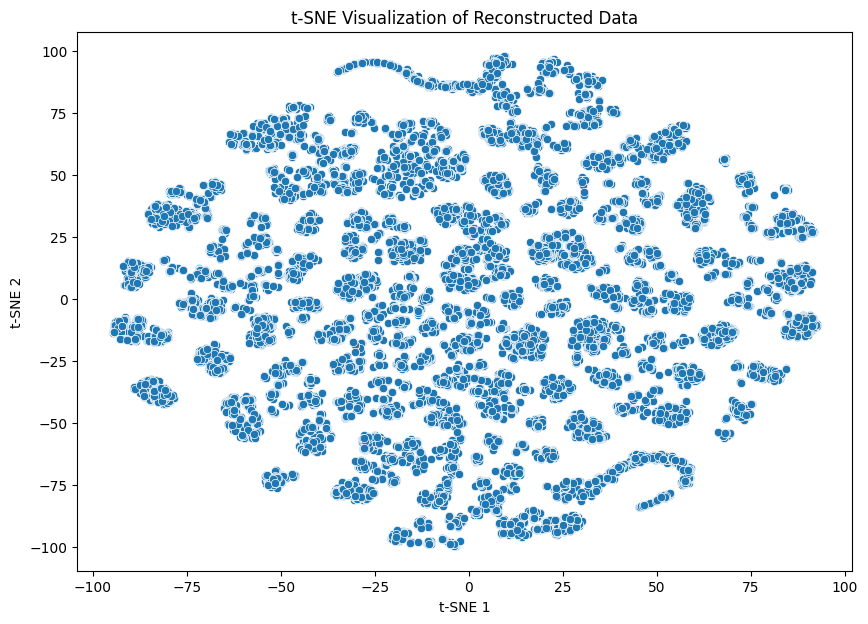

In [118]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=tsne_results[:, 0], y=tsne_results[:, 1])
plt.title('t-SNE Visualization of Reconstructed Data')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

### K-Means

Choosing optimal number of clusters:

In [119]:
from sklearn.cluster import KMeans

inertias = []
k_values = range(2, 30)  # Try values between 2 and 20, for example

for k in tqdm(k_values):
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(tsne_results)
    inertias.append(kmeans.inertia_)

  0%|          | 0/28 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
  4%|▎         | 1/28 [00:01<00:27,  1.03s/it]/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
  7%|▋         | 2/28 [00:01<00:24,  1.04it/s]/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
 11%|█         | 3/28 [00:02<00:24,  1.01it/s]/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will cha

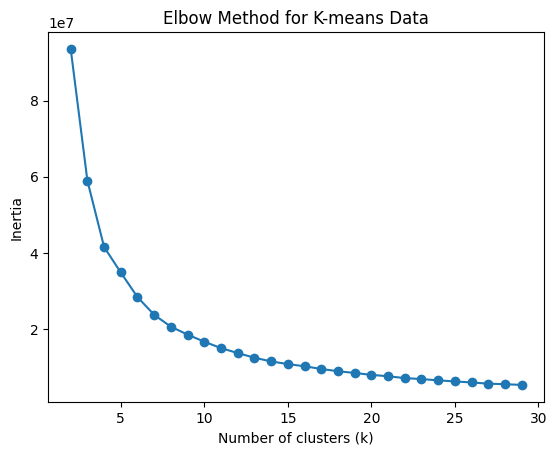

In [120]:
plt.plot(k_values, inertias, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-means Data")
plt.show()

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


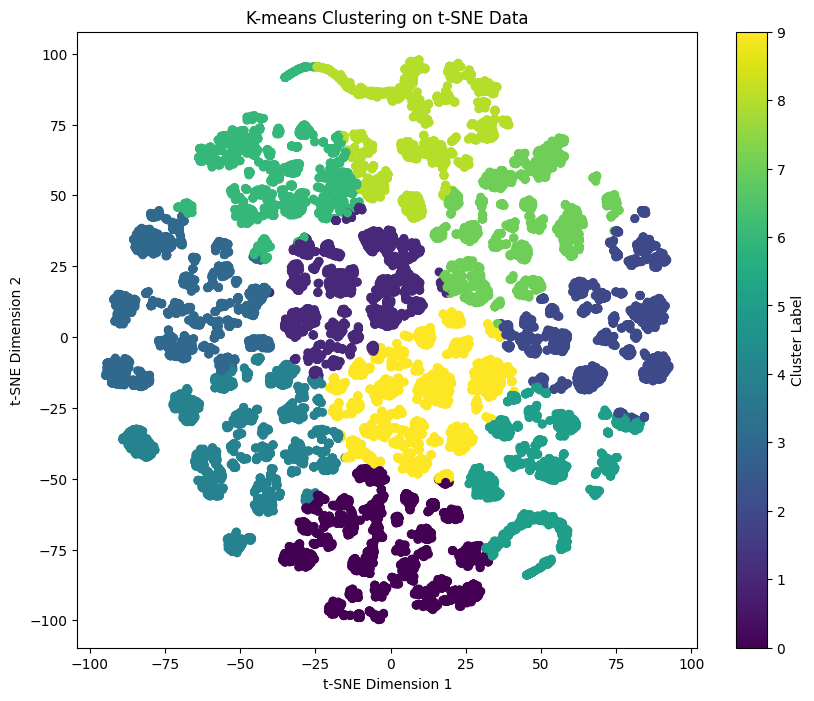

In [121]:
k = 10  # Example number of clusters; adjust based on your needs
kmeans = KMeans(n_clusters=k, random_state=0)
kmeans_labels = kmeans.fit_predict(tsne_results)

# Plotting the results
plt.figure(figsize=(10, 8))
plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=kmeans_labels, cmap='viridis', s=30)
plt.colorbar(label="Cluster Label")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("K-means Clustering on t-SNE Data")
plt.show()

plotting random samples from each cluster:

In [128]:
# Step 1: Find unique cluster labels from K-means
unique_clusters = np.unique(kmeans_labels)

# Step 2: Create a dictionary to store light curves by cluster
clustered_light_curves = {cluster: [] for cluster in unique_clusters}

# Step 3: Populate the dictionary with light curves for each cluster
for i, cluster in enumerate(kmeans_labels):
    clustered_light_curves[cluster].append(filenames_LC_list[i])

# Convert the dictionary to a list of clusters for easier iteration (optional)
clustered_filenames_LC_list = [clustered_light_curves[cluster] for cluster in unique_clusters]

In [129]:
# Parameters
num_samples = 5  # Number of random samples per cluster

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-11-25_1167_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


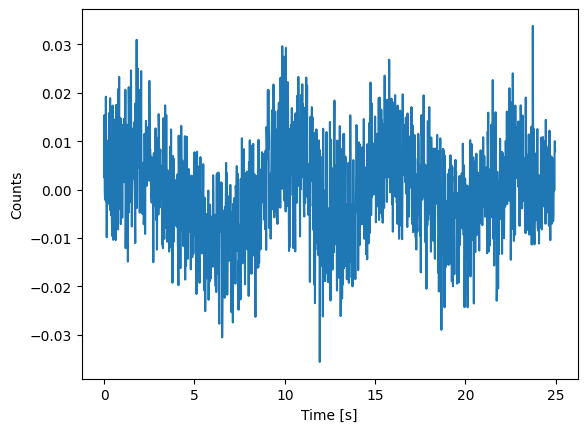

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-10-14_6843_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


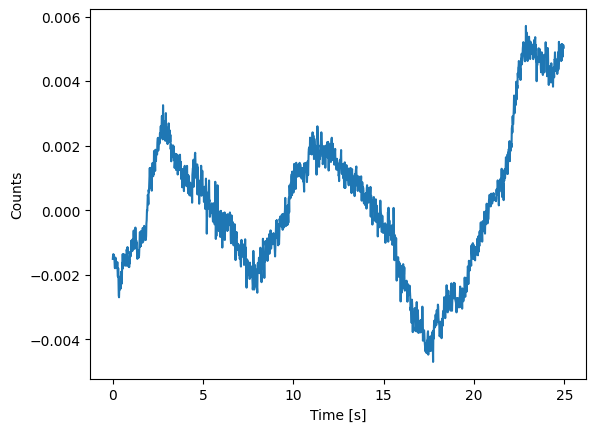

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-01-30_7708_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


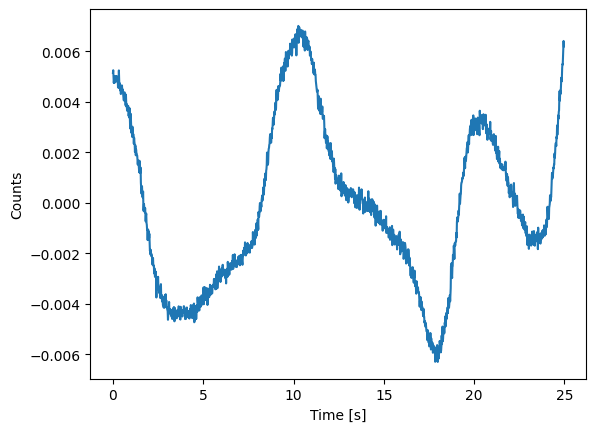

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-09-20_0228_77-21_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


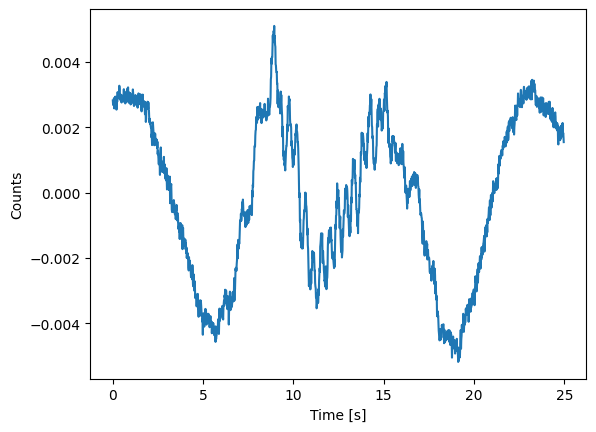

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-01_3770_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


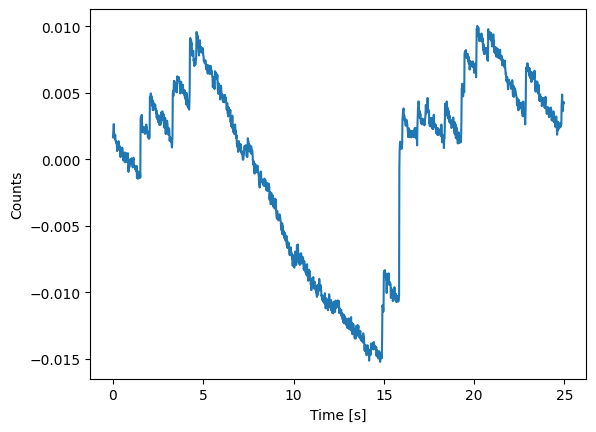

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-03-15_1980_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-2.fits


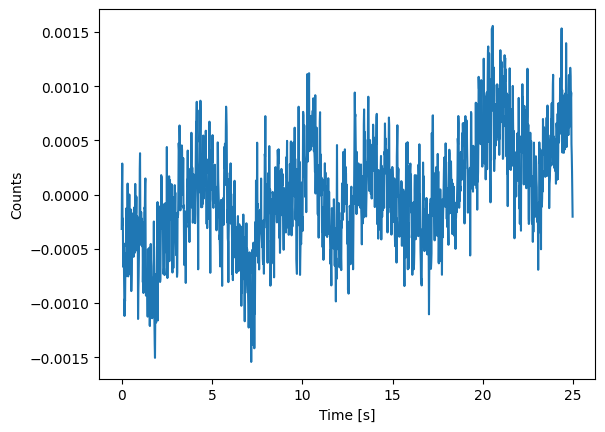

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-08-07_1225_77-21_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


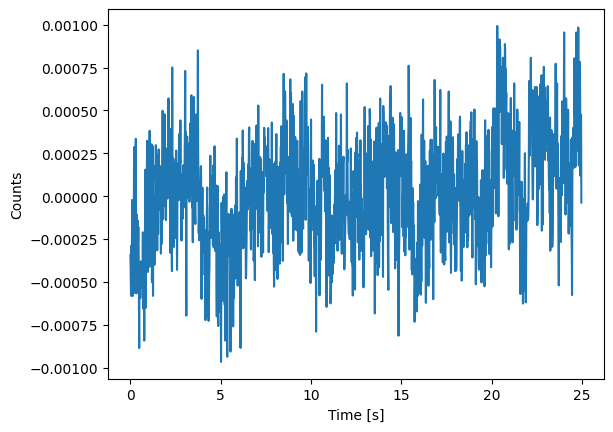

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-08-08_1305_77-21_subscan5_S20mm-SPECPOL-ARRAYDATA-2.fits


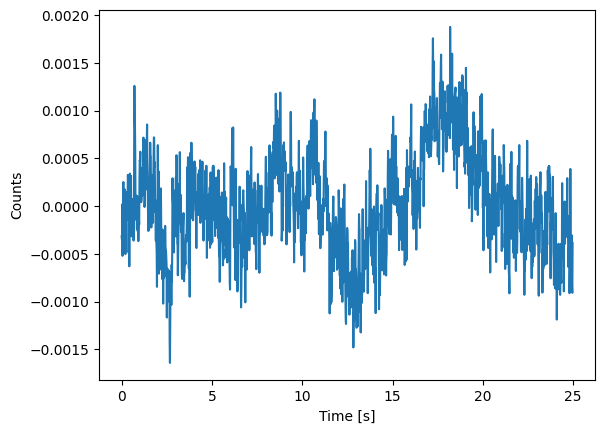

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-11-23_6196_77-21_subscan7_S20mm-SPECPOL-ARRAYDATA-2.fits


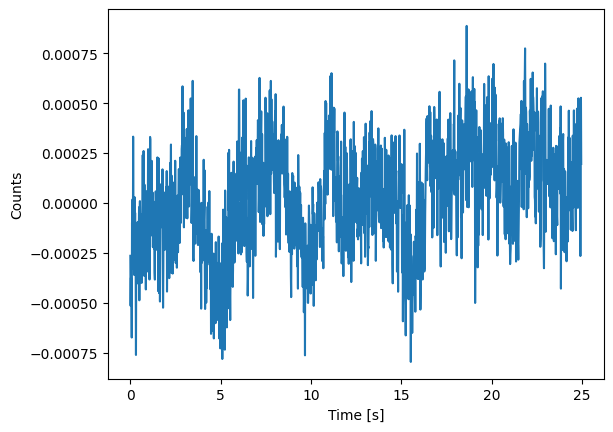

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-10_0408_77-21_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


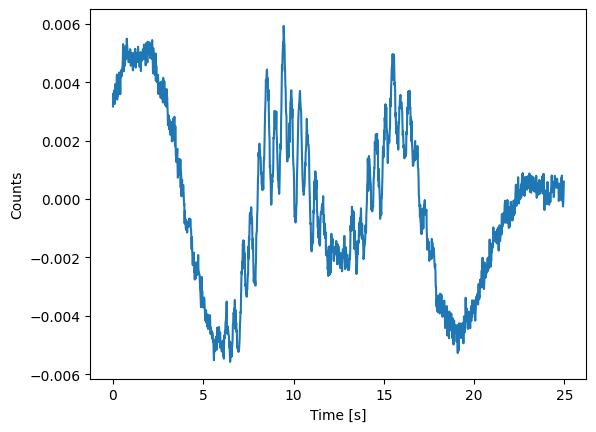

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-03-16_2092_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-2.fits


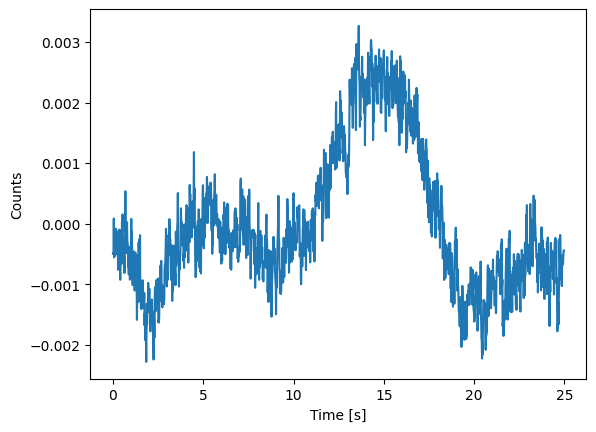

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-30_2479_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-2.fits


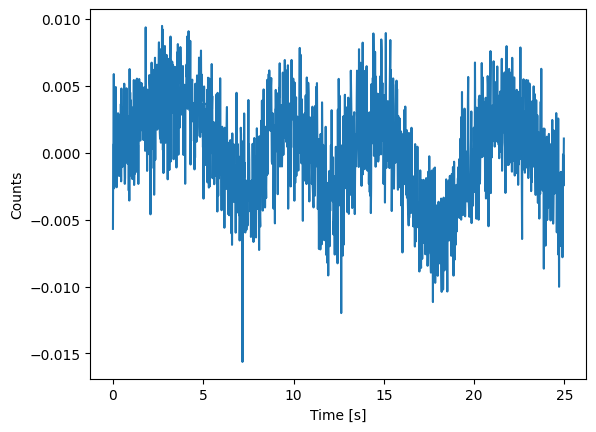

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-01-19_6419_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


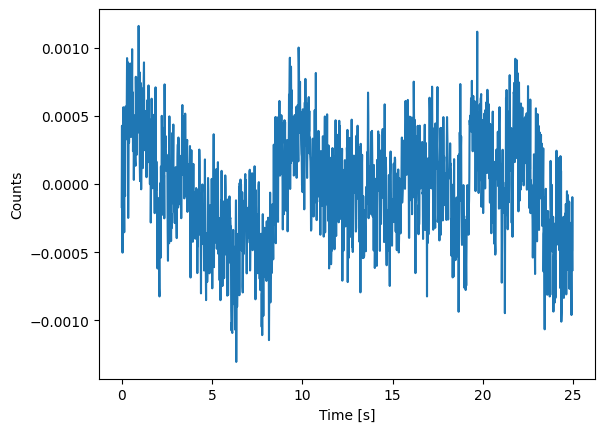

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-06-08_1489_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


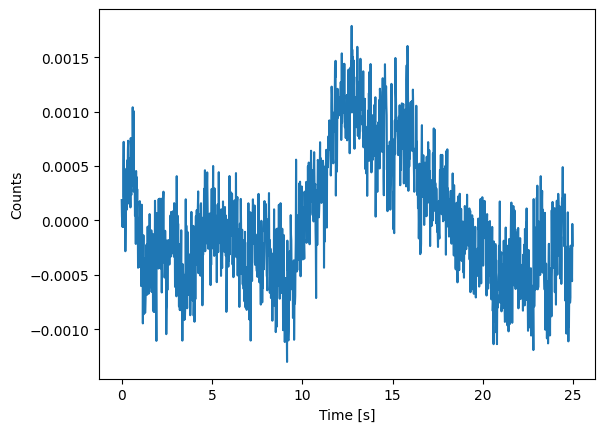

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-01_7628_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-2.fits


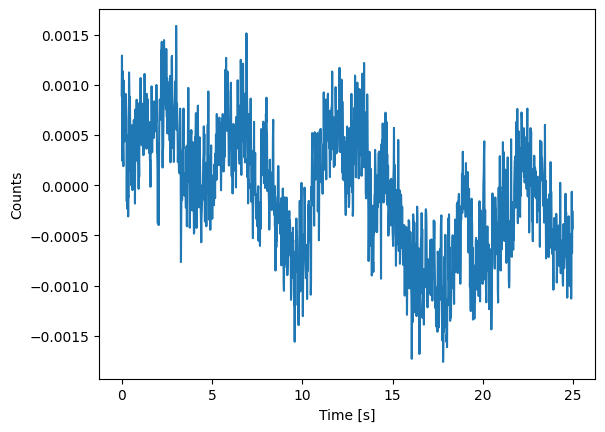

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-06-16_1950_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


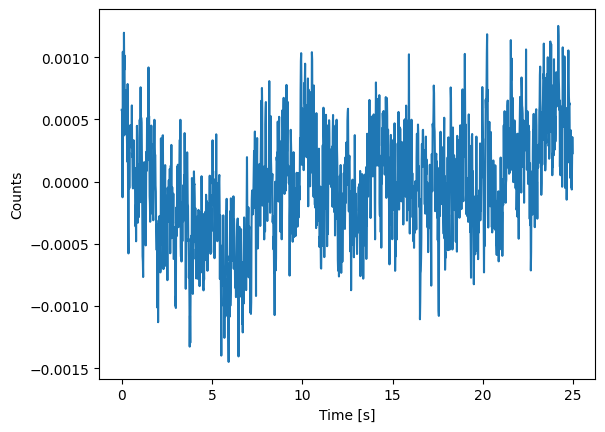

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-10-07_2433_77-21_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


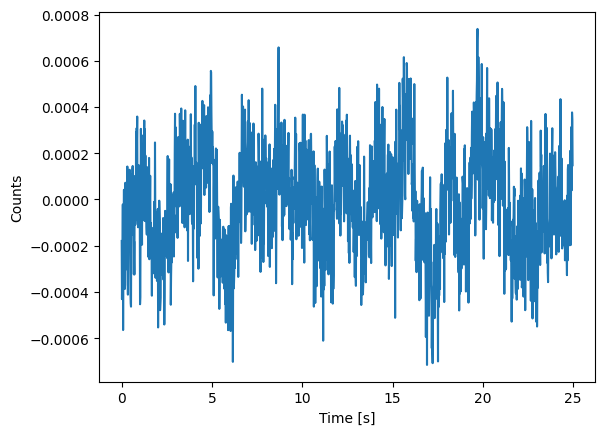

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-01-24_6834_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


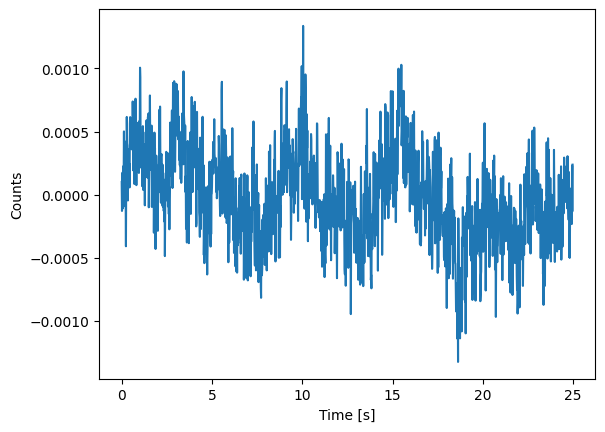

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-09_9070_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


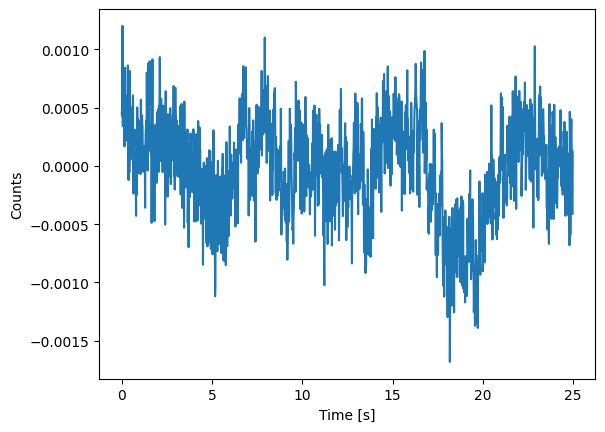

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-12-16_3296_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


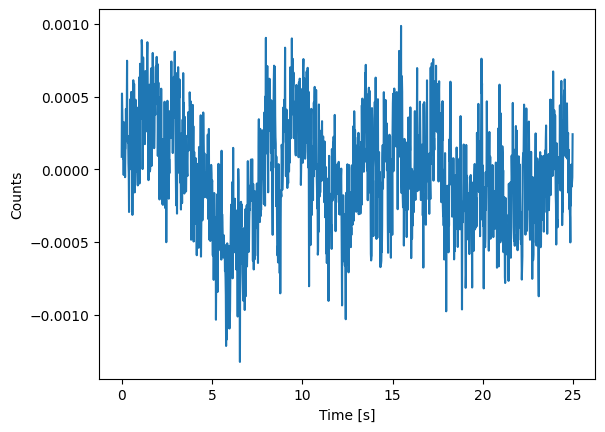

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-01-24_2961_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-2.fits


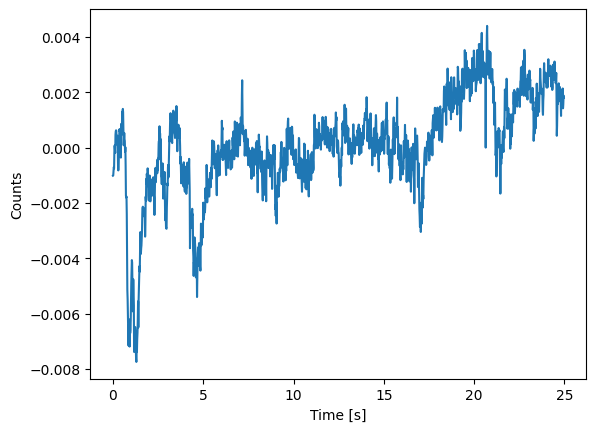

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-10-20_8236_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


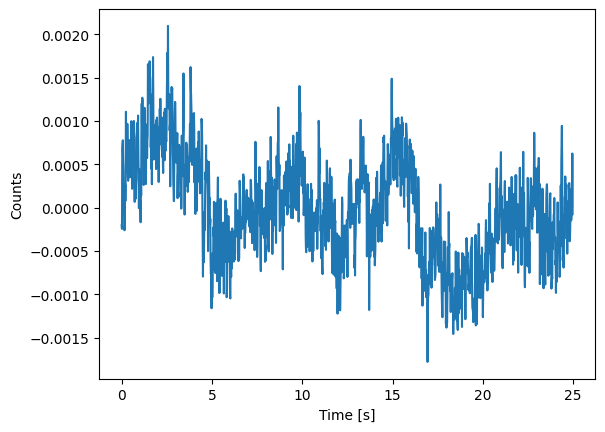

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-08_8975_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


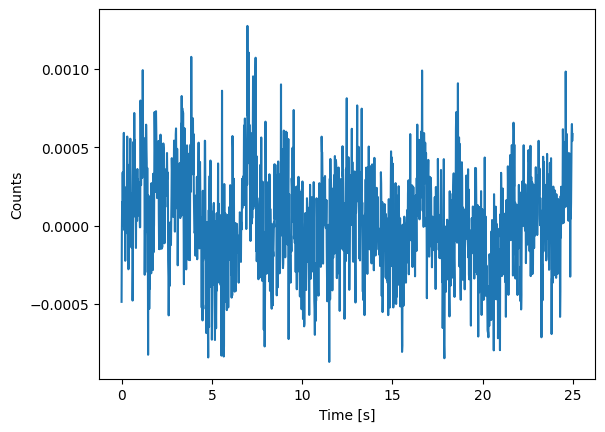

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-09-30_5367_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


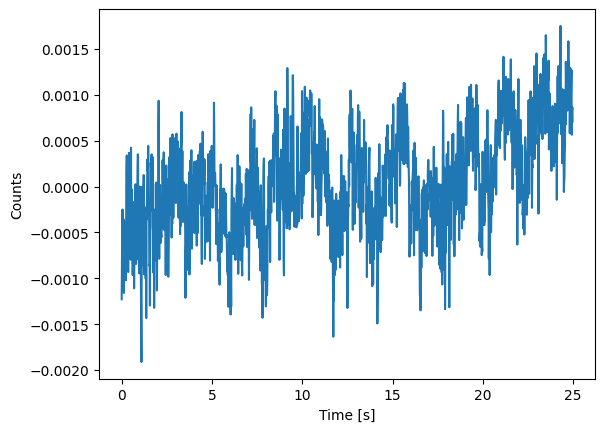

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-01-24_3031_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-2.fits


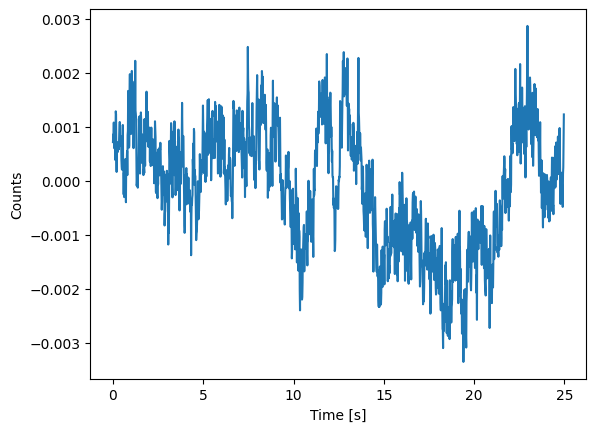

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-01_3770_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-2.fits


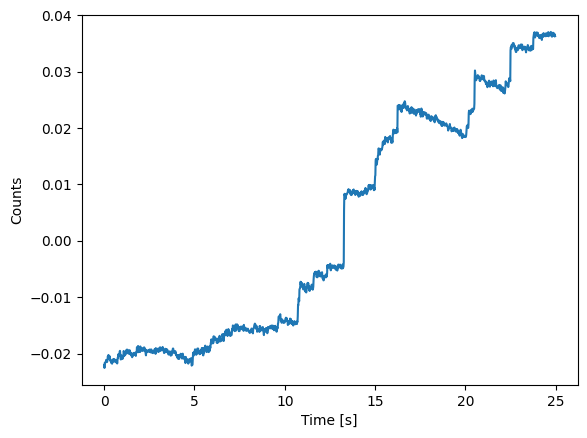

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-07-09_8711_77-21_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


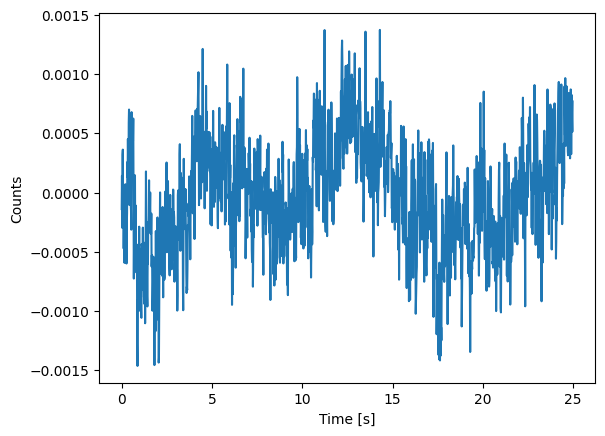

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-10_0263_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


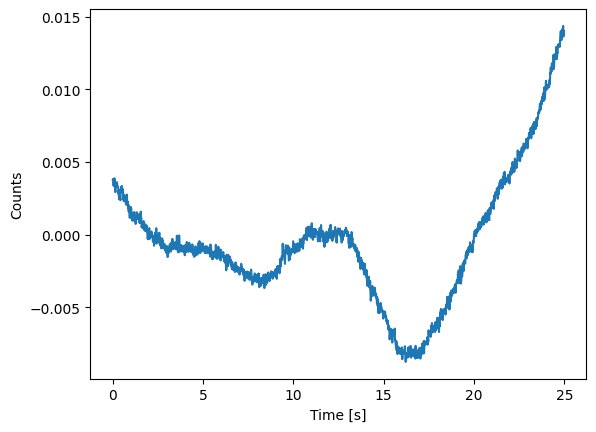

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-09_9054_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


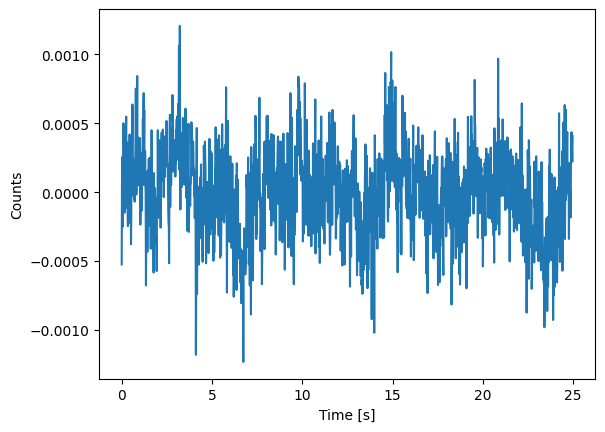

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-20_0355_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


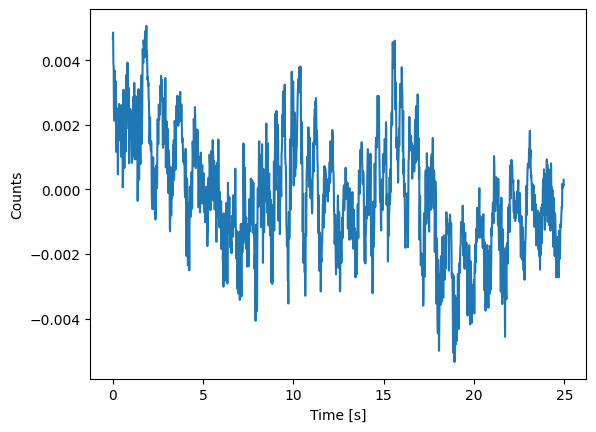

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-10-24_3790_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-2.fits


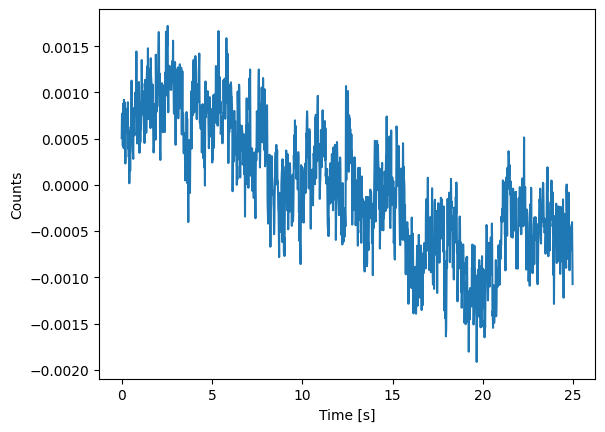

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-09-19_4862_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


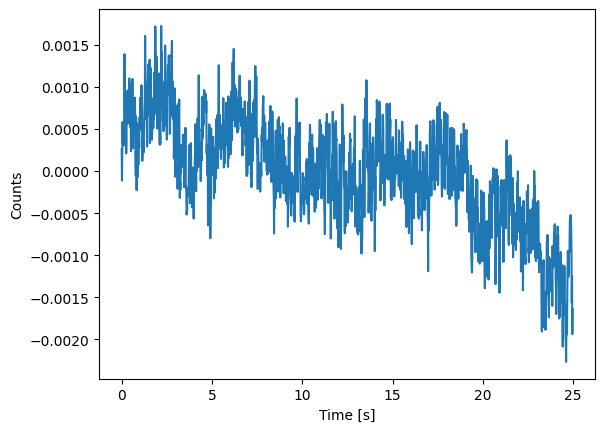

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-25_6339_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


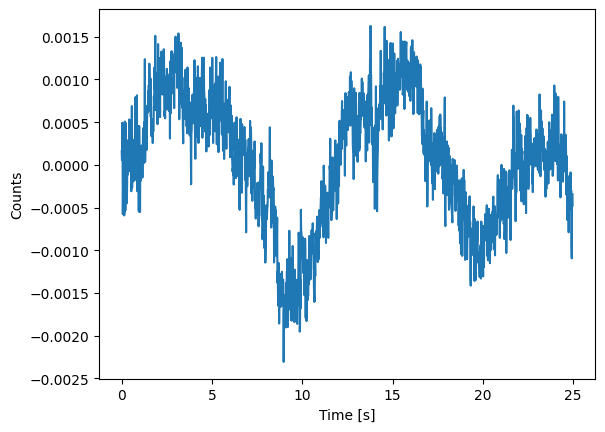

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-06-15_1839_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


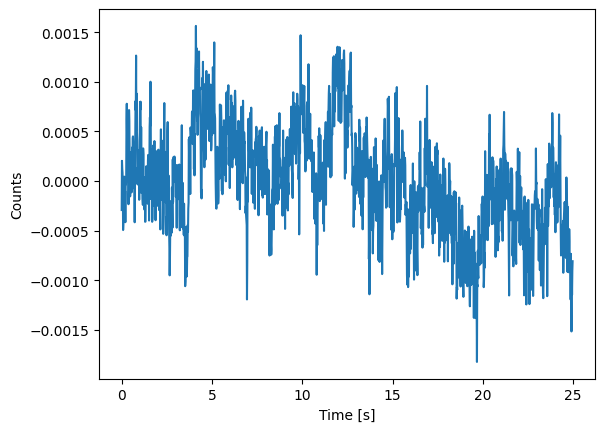

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-21_0485_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-2.fits


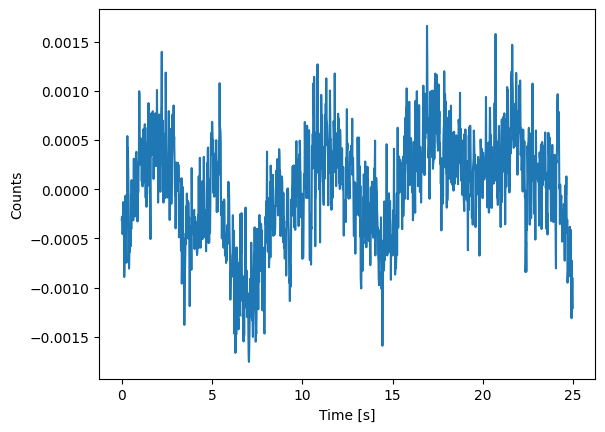

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-04-05_4299_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


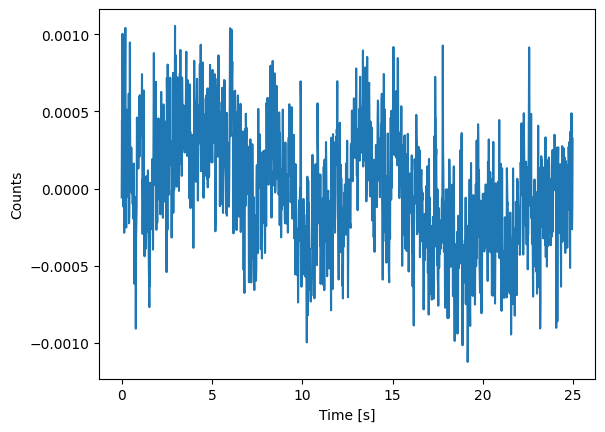

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-06-16_1946_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-2.fits


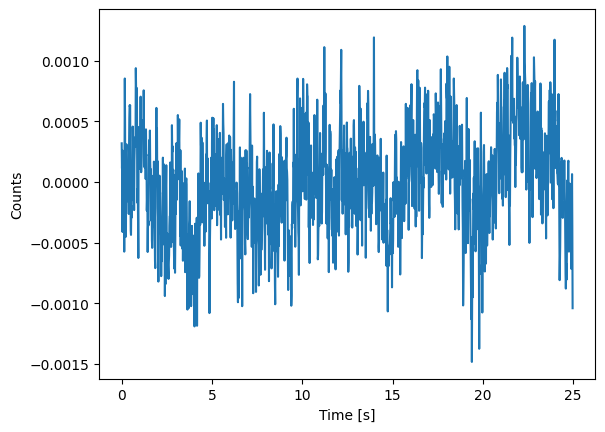

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-09-20_4916_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


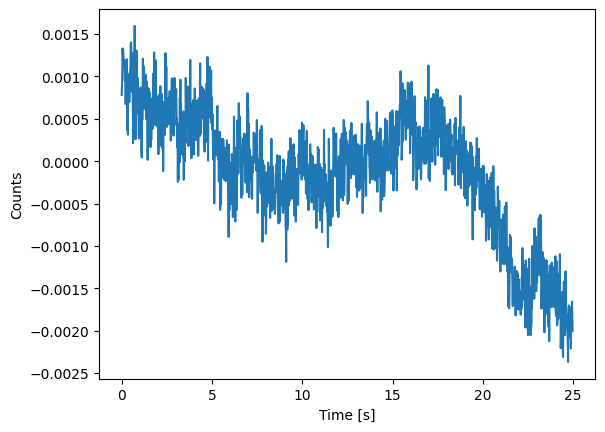

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-02-27_6389_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


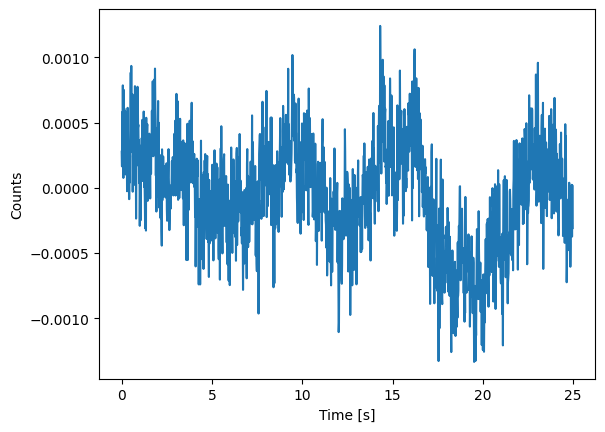

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-11-25_1169_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


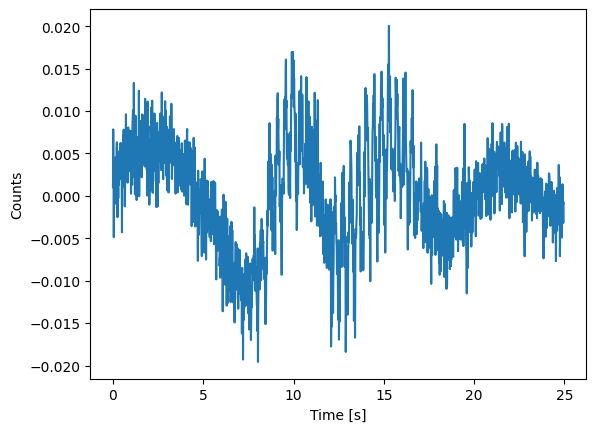

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-10-20_8250_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


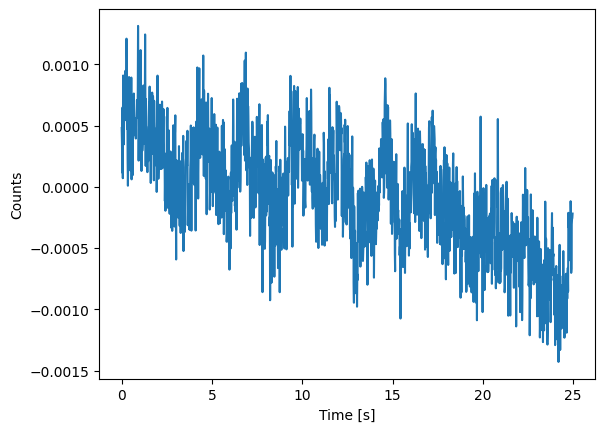

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-05-29_5516_77-21_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


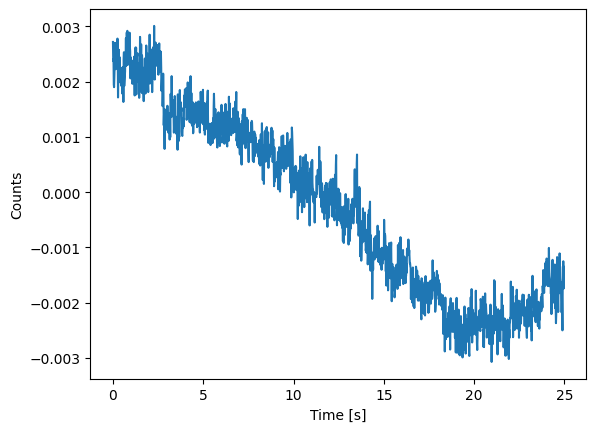

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-02_7862_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


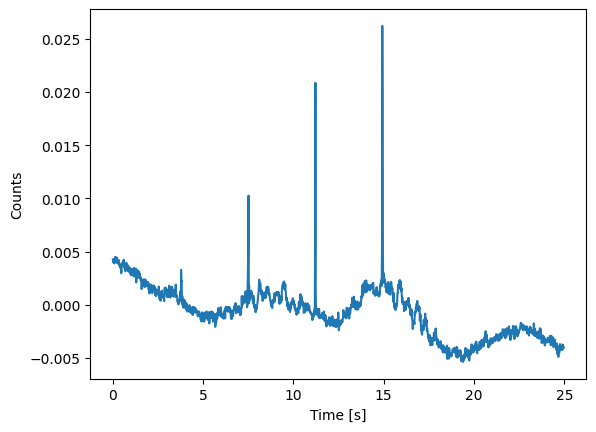

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-10-14_6905_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-1.fits


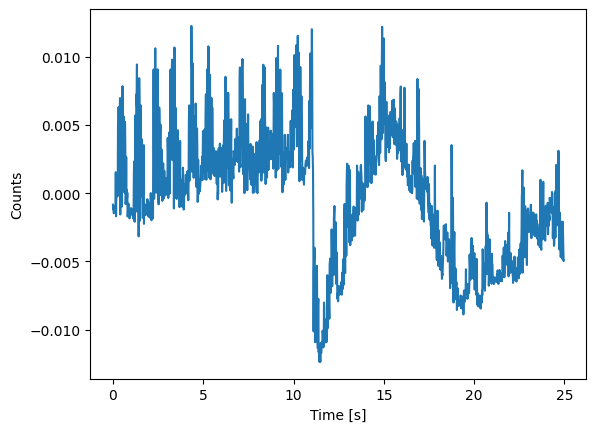

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-07-25_9949_77-21_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


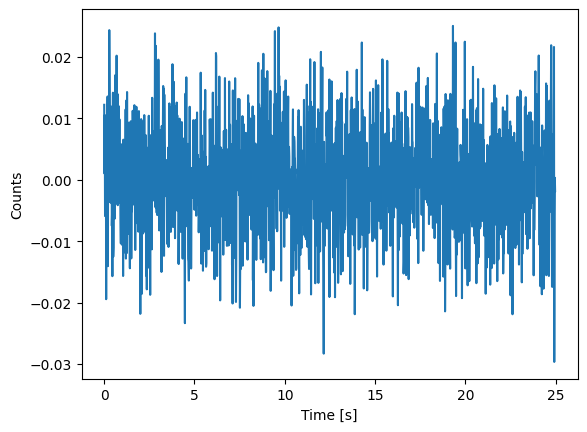

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-01_7797_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


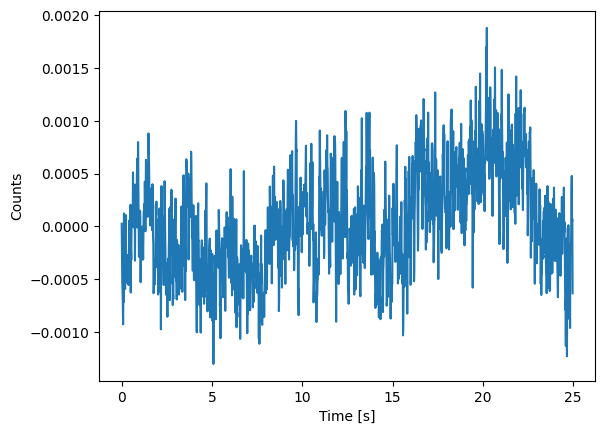

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-17_9139_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


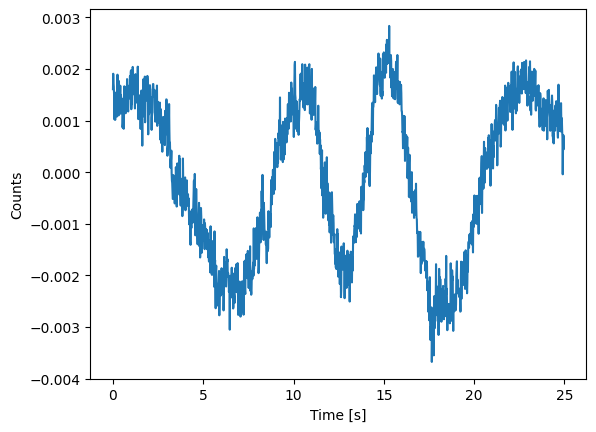

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-12_4965_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


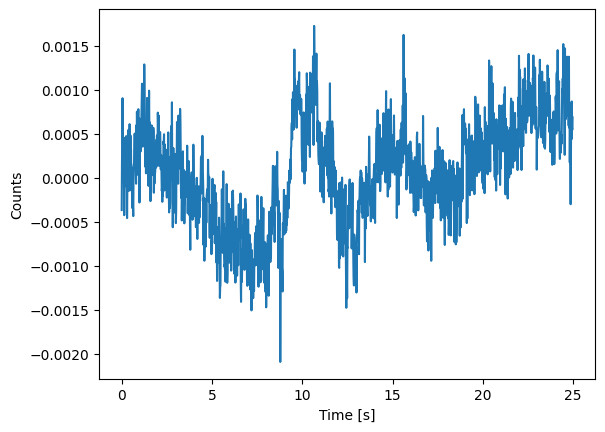

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-04-04_4261_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-2.fits


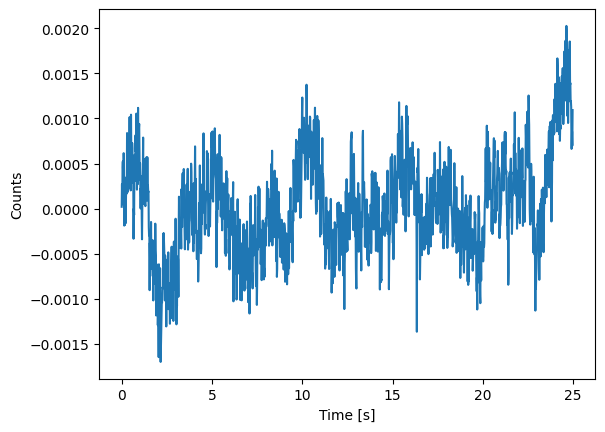

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-10-24_3872_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-2.fits


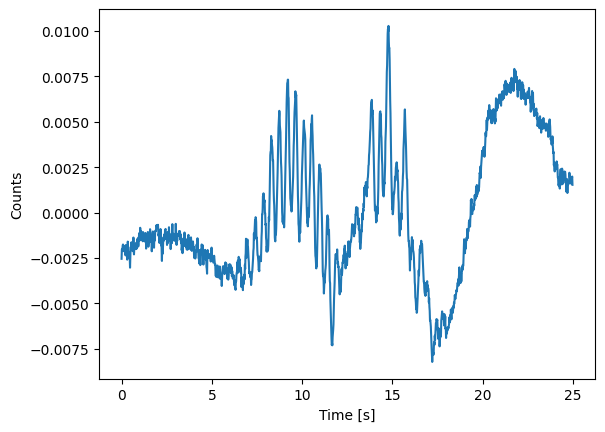

In [130]:
# Step 4: Iterate over each cluster and plot random samples
for cluster_id, filenames_LC_sublist in enumerate(clustered_filenames_LC_list):
    display(HTML(f"<h2>Cluster {cluster_id}: There are {len(filenames_LC_sublist)} Lightcurves in this Cluster</h2>"))
    
    # Step 5: Randomly select a subset of light curves from this cluster
    samples = random.sample(filenames_LC_sublist, min(num_samples, len(filenames_LC_sublist)))
    
    # Step 6: Plot each selected light curve
    for filename, LC in samples:
        print(f"Filename: {filename}")
        plot_lc(LC)  # Plot the light curve using your custom plot function

### DBSCAN

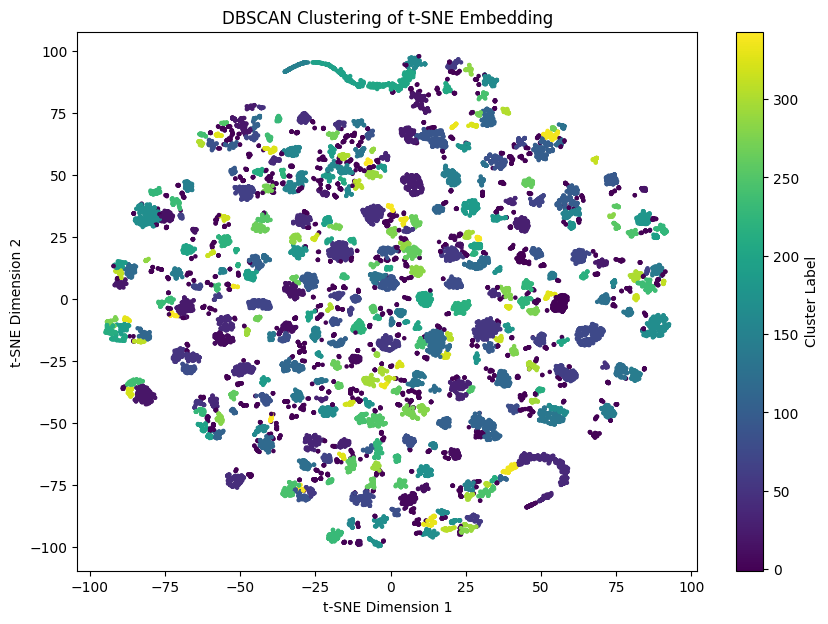

In [122]:
from sklearn.cluster import DBSCAN

# Apply DBSCAN on the t-SNE embedding
dbscan = DBSCAN(eps=1.5, min_samples=25)  # Adjust eps and min_samples for your data
clusters = dbscan.fit_predict(tsne_results)

# Visualize the clustering results, where -1 represents outliers
plt.figure(figsize=(10, 7))
plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=clusters, cmap='viridis', s=5)
plt.title('DBSCAN Clustering of t-SNE Embedding')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.colorbar(label='Cluster Label')
plt.show()


In [123]:
# Step 1: Find unique cluster labels
unique_clusters = np.unique(clusters)

# Step 2: Create a dictionary to store light curves by cluster
clustered_light_curves = {cluster: [] for cluster in unique_clusters}

# Step 3: Populate the dictionary with light curves for each cluster
for i, cluster in enumerate(clusters):
    clustered_light_curves[cluster].append(filenames_LC_list[i])

# If you prefer lists instead of a dictionary
clustered_filenames_LC_list = [clustered_light_curves[cluster] for cluster in unique_clusters]

### Plot Random Samples from each Cluster

In [124]:
len(unique_clusters)

345

In [125]:
num_samples = 5

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-12-02_7372_77-21_subscan6_S20mm-SPECPOL-ARRAYDATA-2.fits


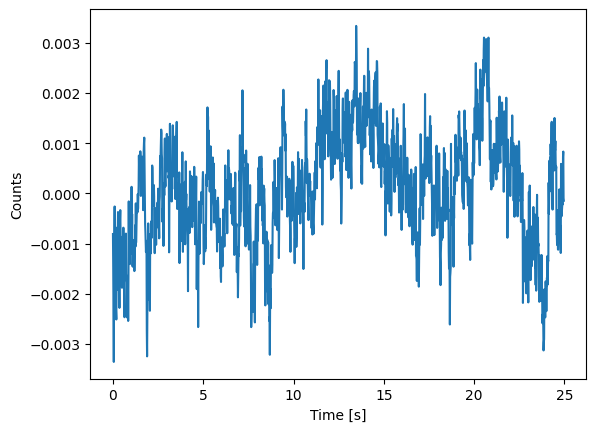

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-08_9039_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


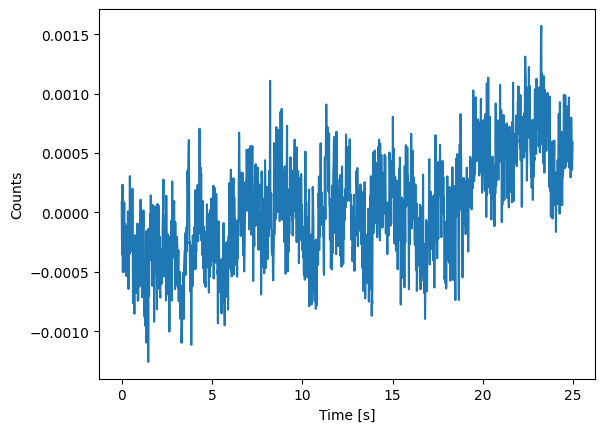

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-05-17_4496_77-21_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


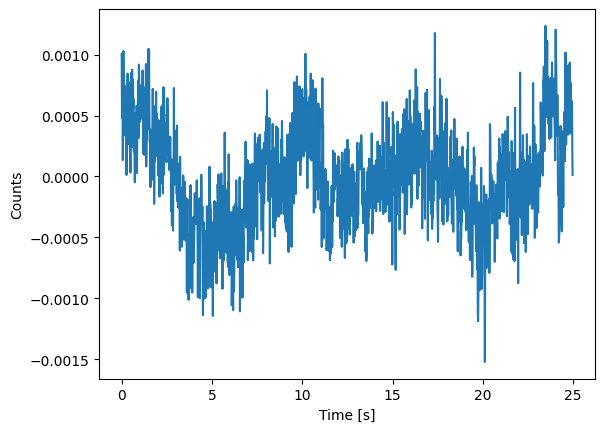

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-10-08_2570_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


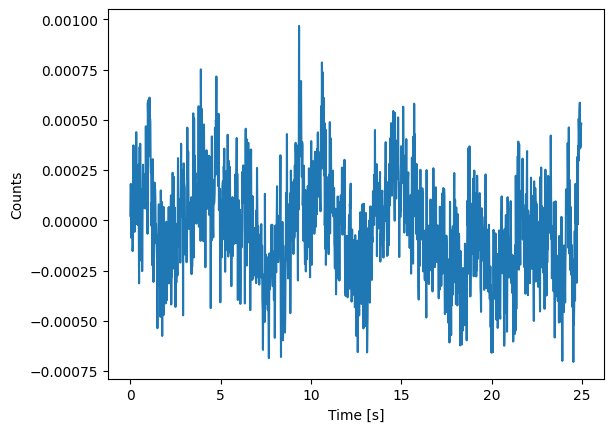

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-18_9385_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


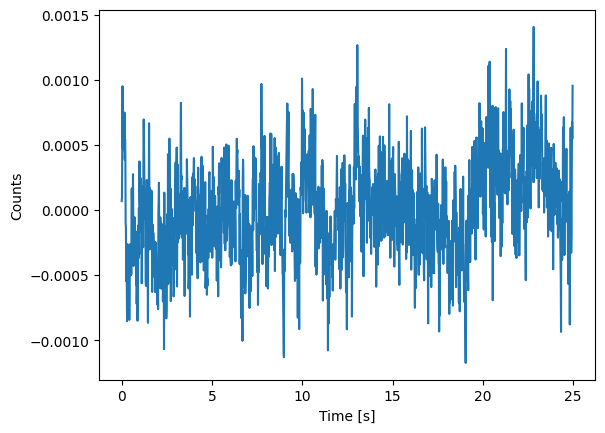

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-22_0664_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


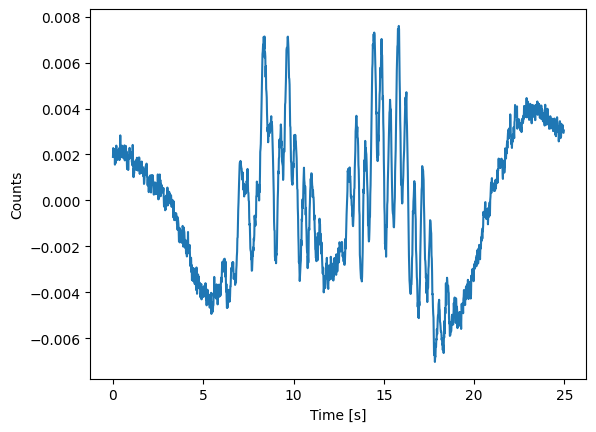

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-01_7808_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


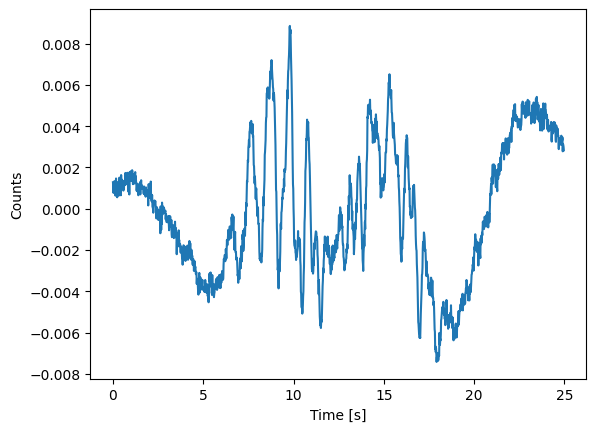

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-01_3771_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-2.fits


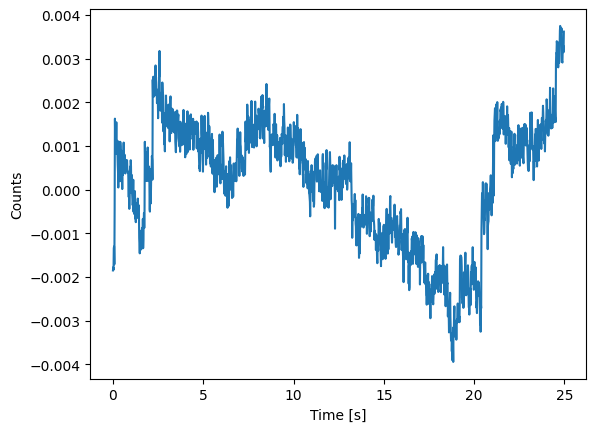

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-22_9636_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


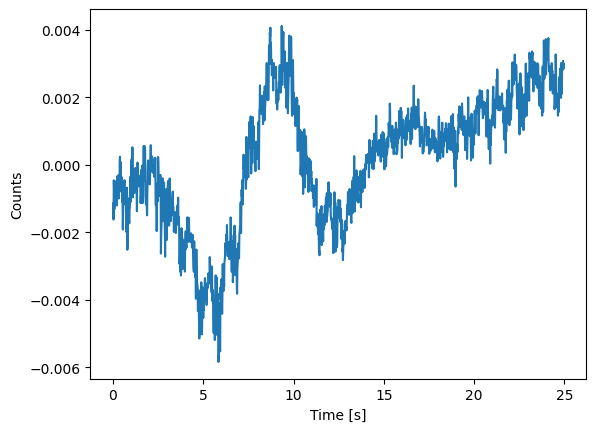

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-09-30_5734_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


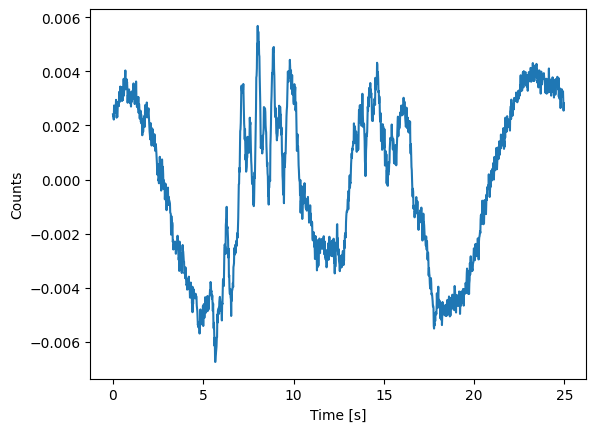

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-10-08_2546_77-21_subscan6_S20mm-SPECPOL-ARRAYDATA-2.fits


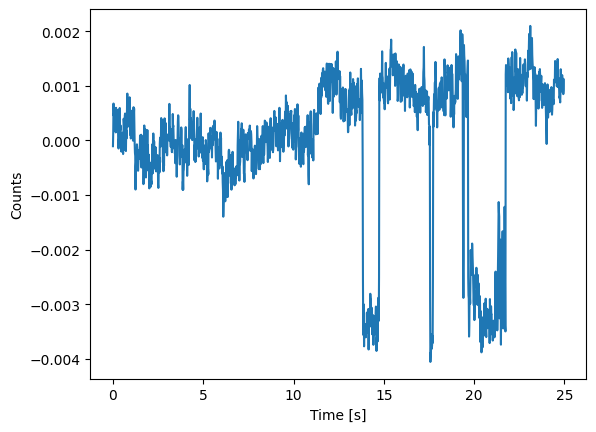

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-10-07_2444_77-21_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


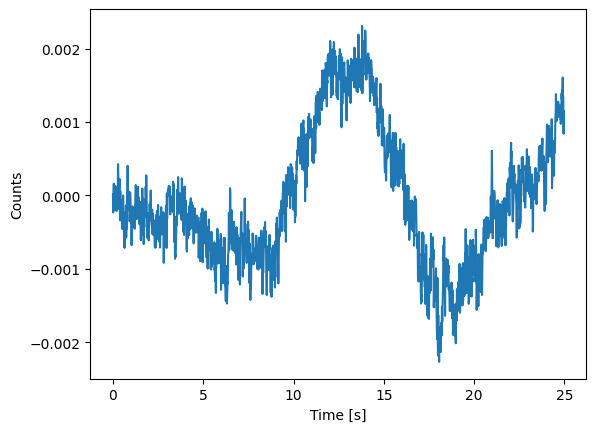

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-03-01_1244_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


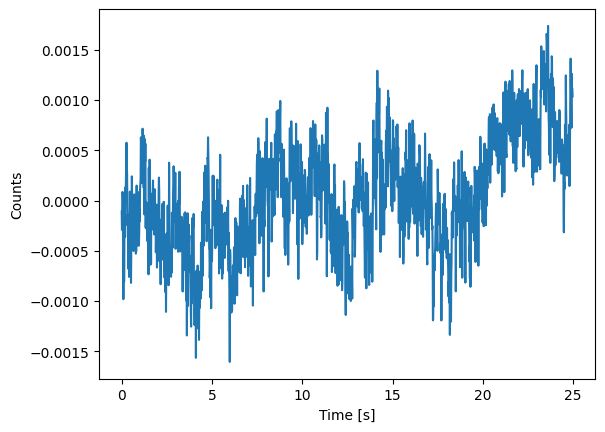

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-11-10_9532_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


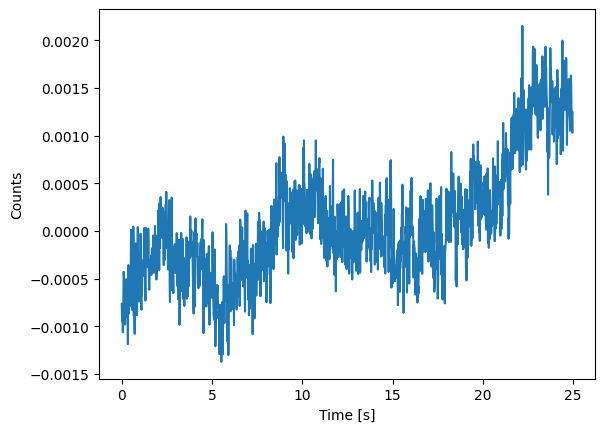

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-01-30_7705_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


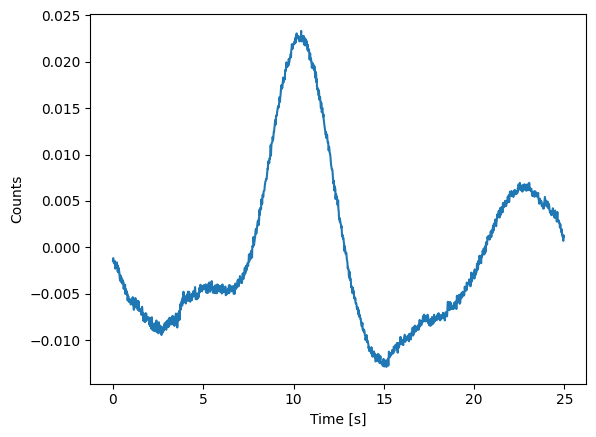

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-04-05_4281_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


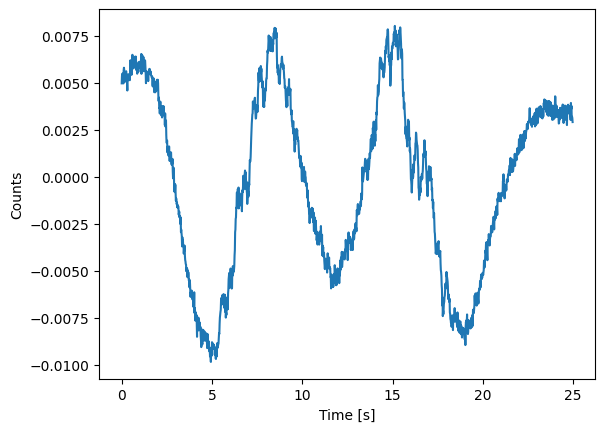

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-11-25_1167_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-2.fits


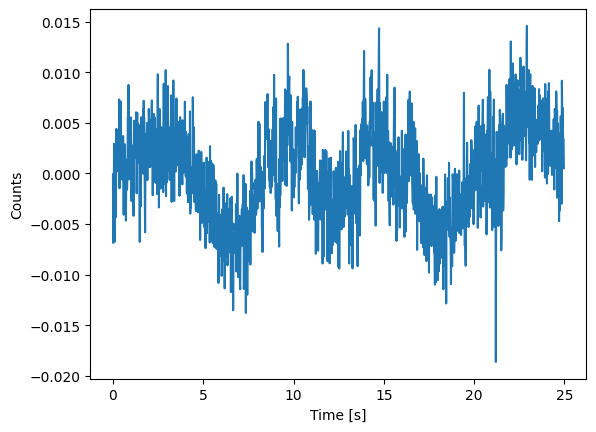

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-02-13_5335_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


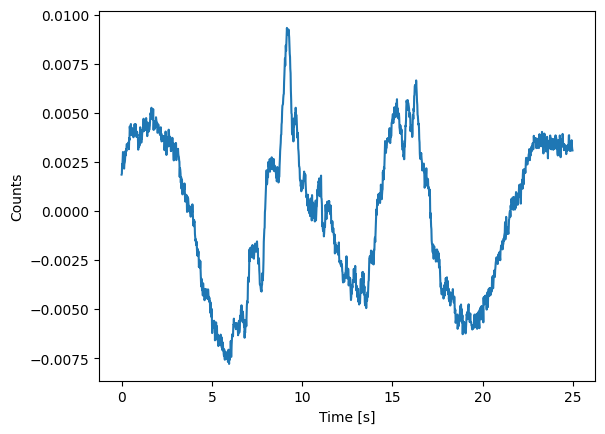

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-01_7668_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


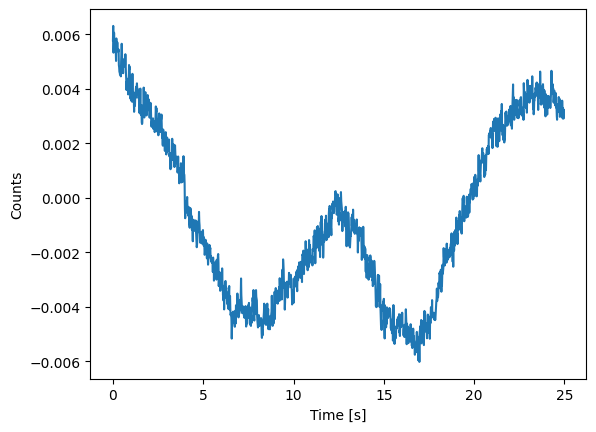

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-10_0405_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


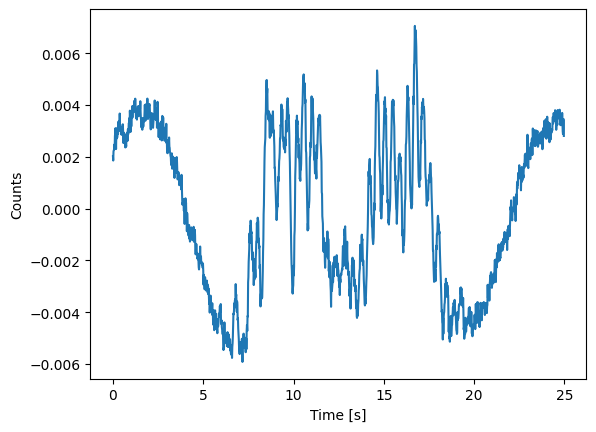

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-03-22_2768_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-1.fits


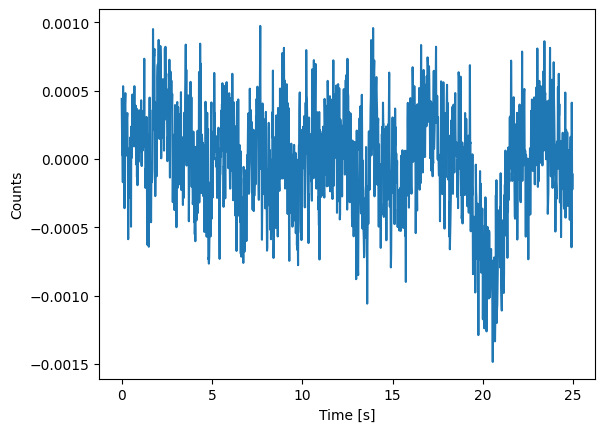

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-01-19_6404_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-2.fits


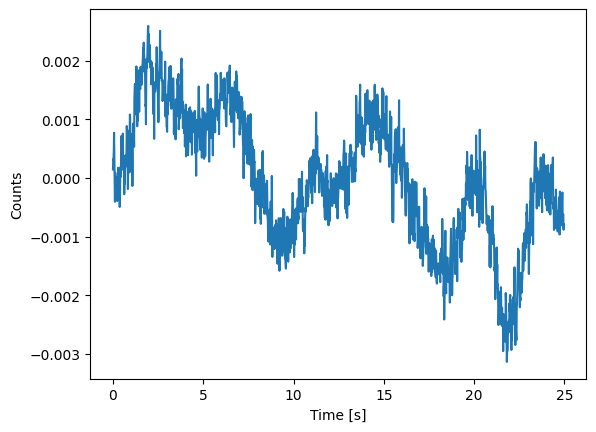

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-01-24_2953_77-21_subscan1_S20mm-SPECPOL-ARRAYDATA-2.fits


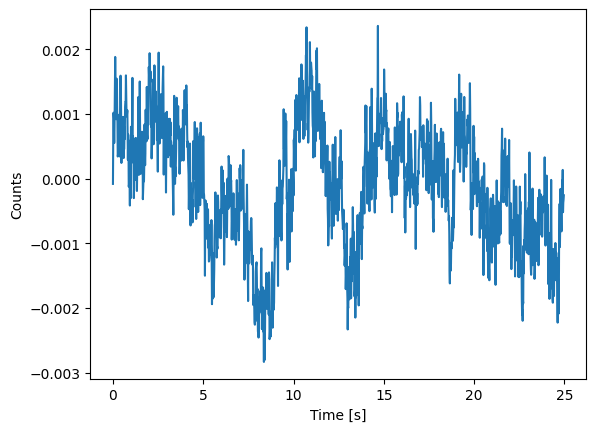

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-06-16_6507_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


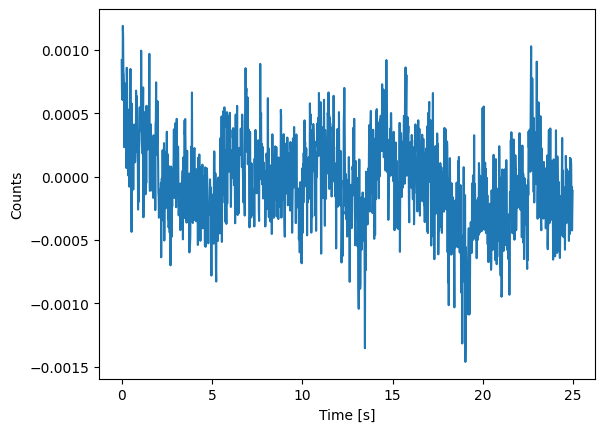

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-06-16_2002_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-2.fits


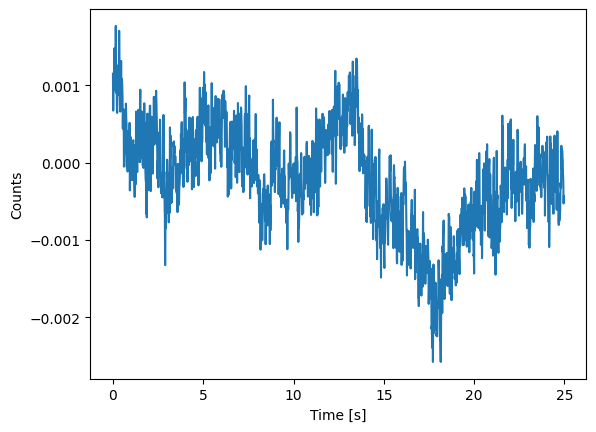

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-08-22_2257_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


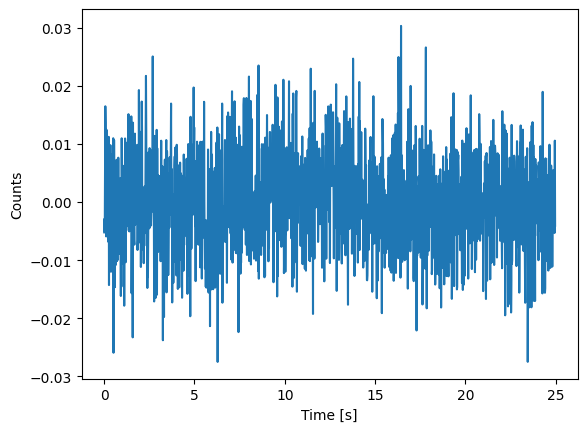

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-12-16_3299_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-2.fits


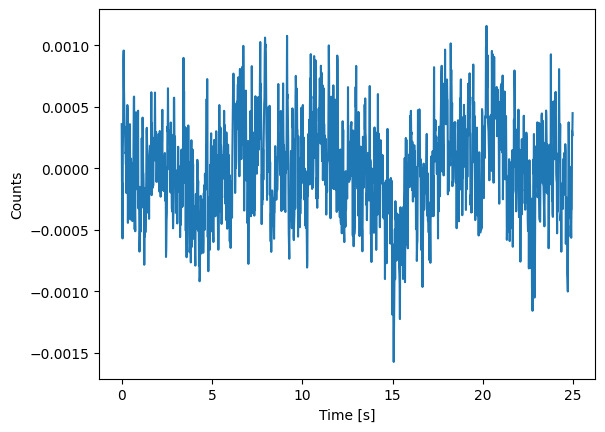

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8357_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


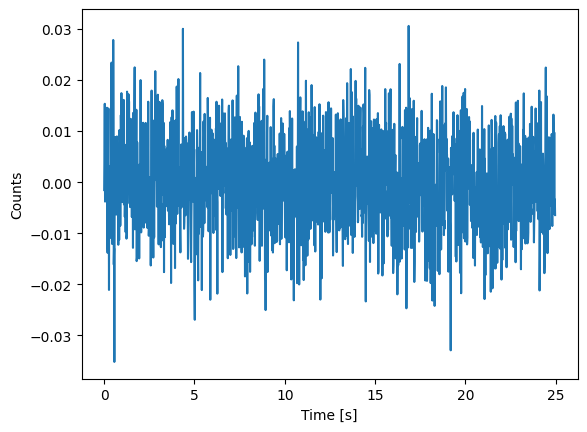

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-08-07_1120_77-21_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


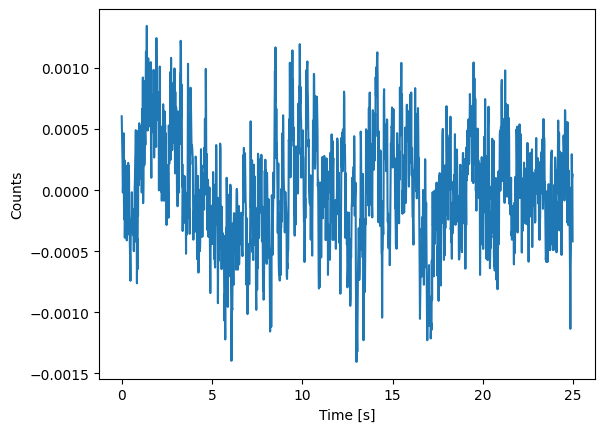

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-11_0430_77-21_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


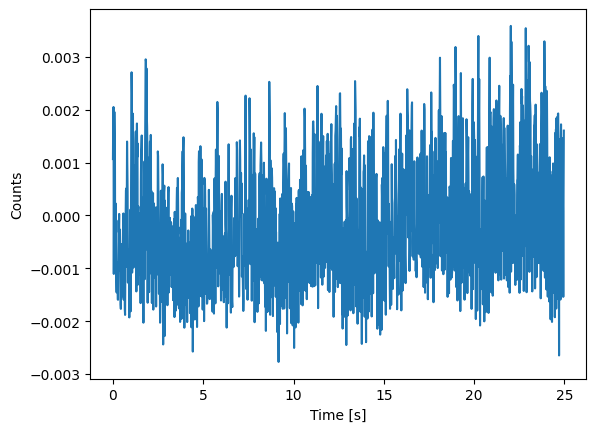

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-01-24_2957_77-21_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


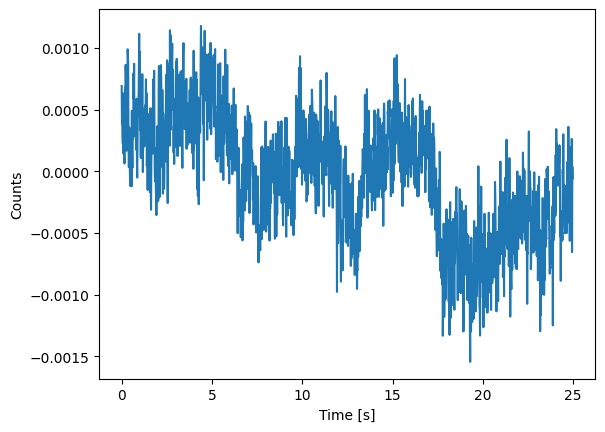

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-09_0156_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-2.fits


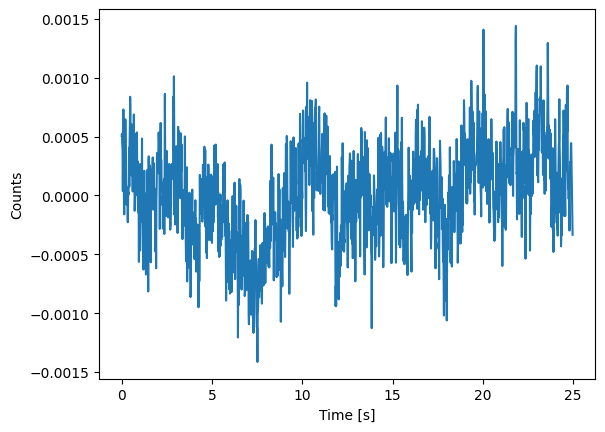

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-06-16_6470_77-21_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


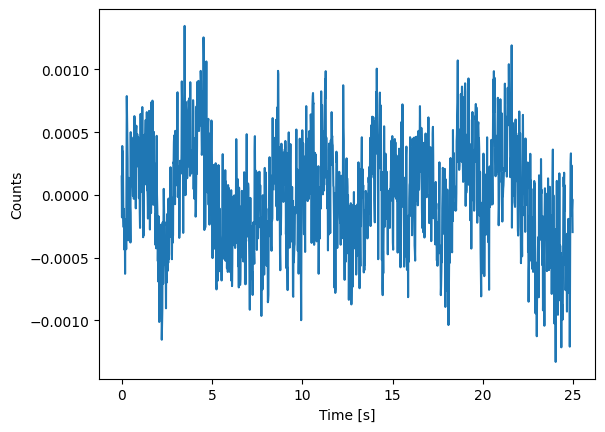

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-02-27_6364_77-21_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


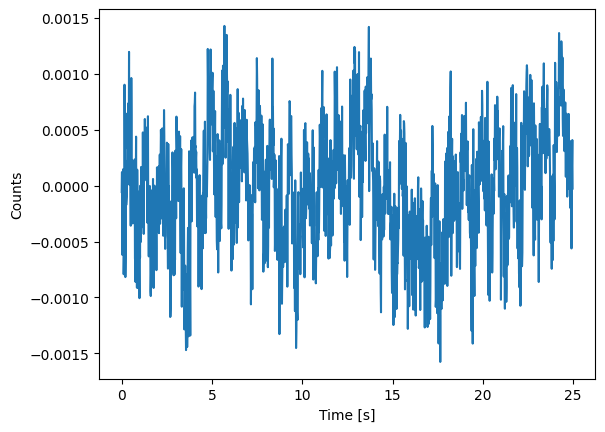

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-21_0533_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


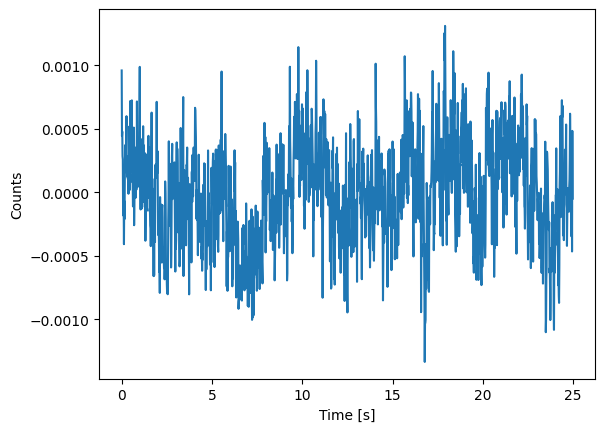

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-09-20_0211_77-21_subscan7_S20mm-SPECPOL-ARRAYDATA-2.fits


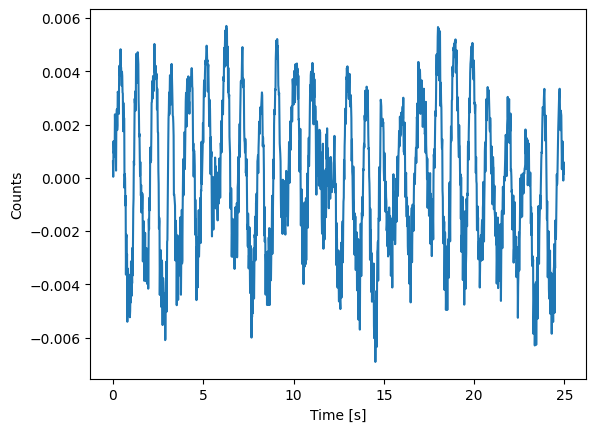

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-25_6351_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


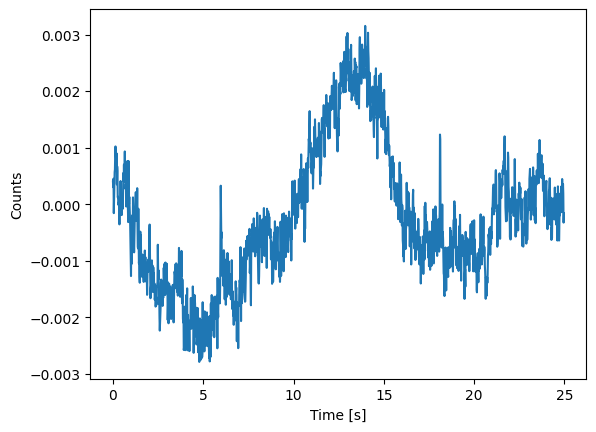

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-17_9214_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-2.fits


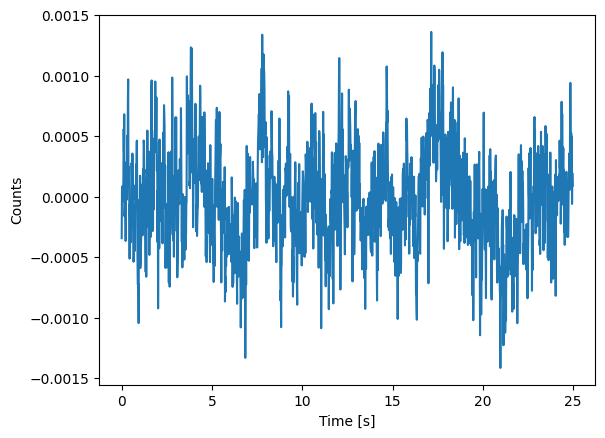

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-28_0645_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


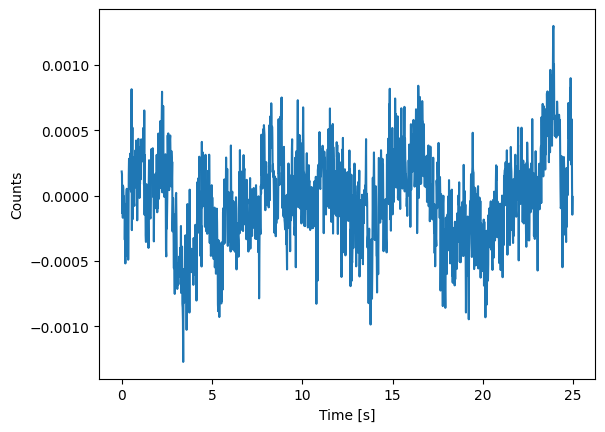

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-03-22_2825_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


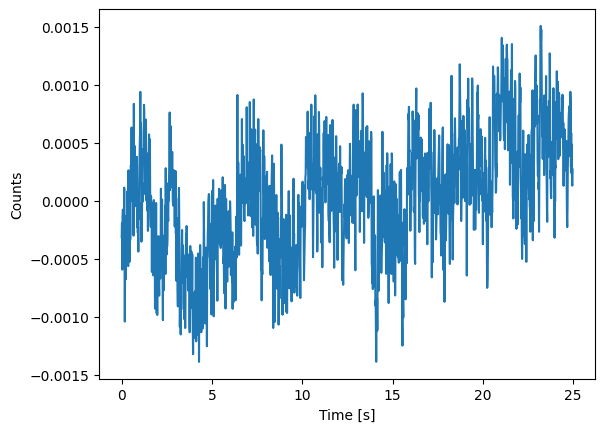

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-09-30_5375_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


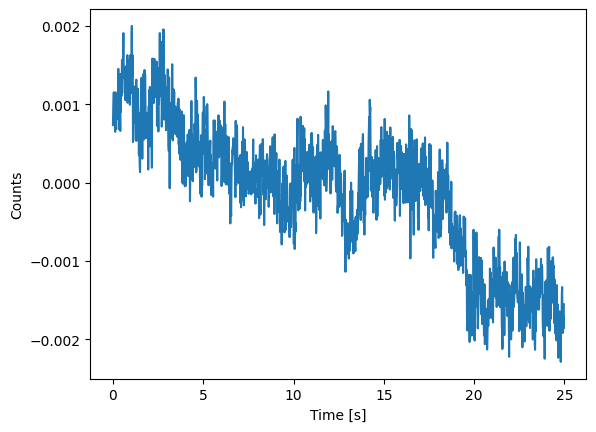

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-06-30_3708_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


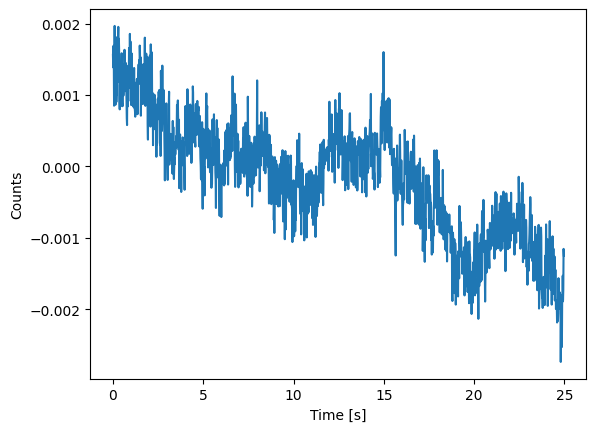

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-01-03_4938_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


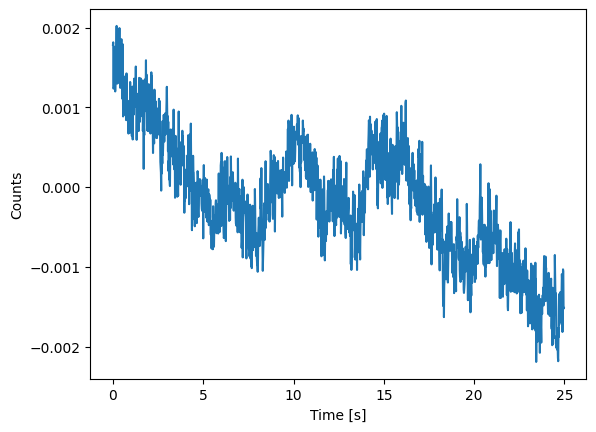

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-09-30_5322_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-2.fits


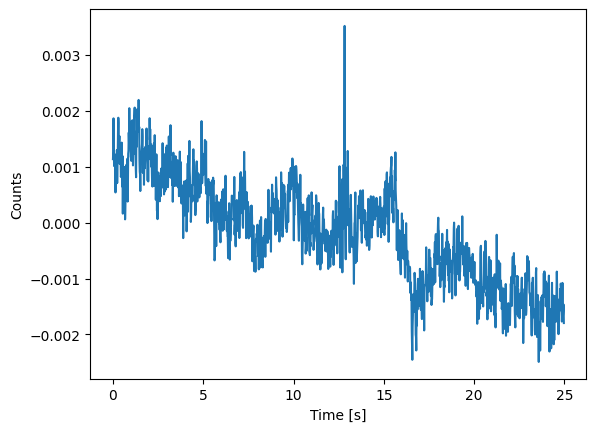

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-10-14_6956_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-2.fits


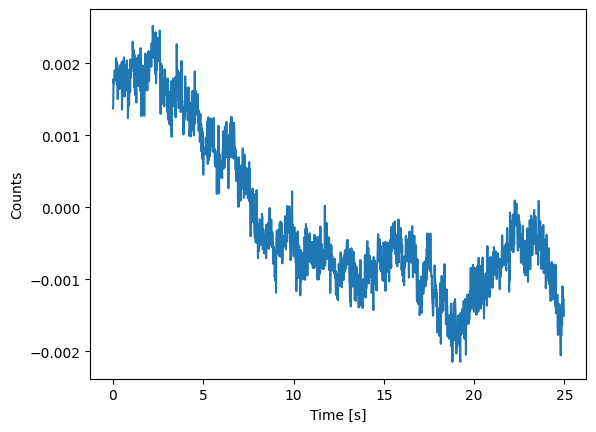

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-30_2554_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


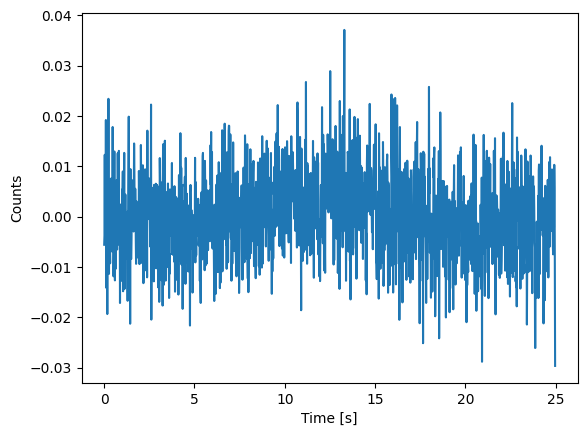

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-30_2629_77-21_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


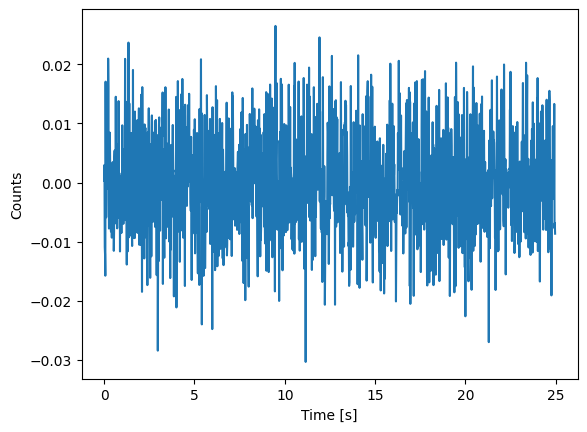

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-07-28_0167_77-21_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


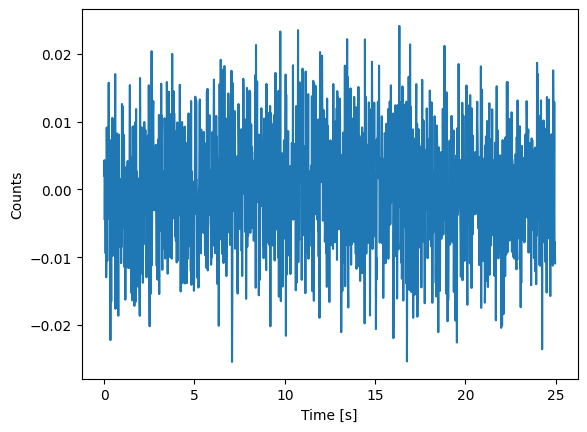

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-20_0322_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


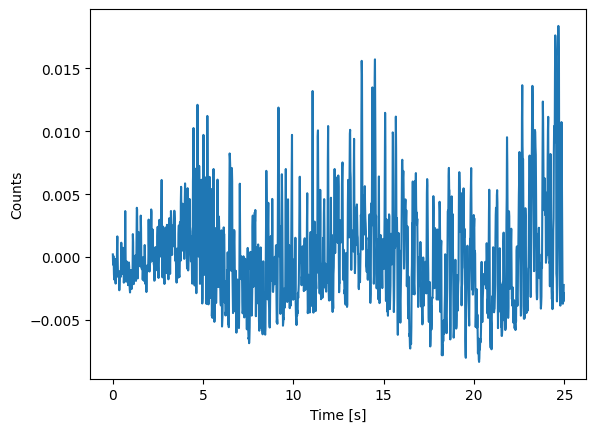

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-08-22_2201_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


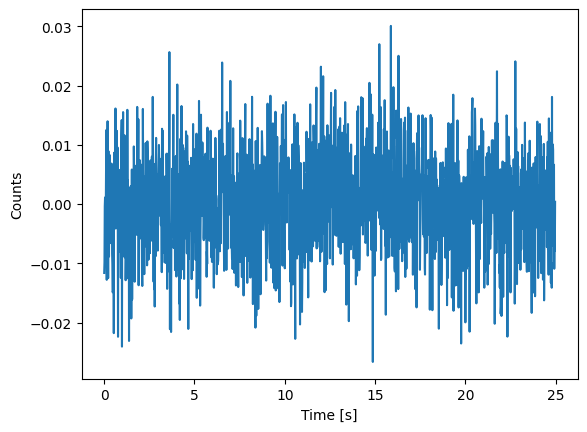

In [127]:
from IPython.display import display, HTML
for cluster_id in unique_clusters[10:20]:
    clustered_light_curves_sub = clustered_light_curves[cluster_id]
    display(HTML(f"<h2>Cluster {cluster_id}:  There are {len(clustered_light_curves_sub)} Lightcurves in this Cluster</h2>"))
    samples = random.sample(clustered_light_curves_sub, min(num_samples, len(clustered_light_curves_sub)))

    for filename, LC in samples:
        print(filename)
        plot_lc(LC)

In [80]:
len(set(cluster_labels))

4

In [79]:
lightcurves = [item[1] for item in filtered_filenames_LC_list]
file_paths = [item[0] for item in filtered_filenames_LC_list]
filenames = [os.path.basename(path) for path in file_paths]

In [84]:
# Example: Plot light curves from one of the clusters
import random

cluster_num = 3  # Choose a cluster number to analyze
cluster_indices = np.where(cluster_labels == cluster_num)[0]

print(f"Sample Light Curves from Cluster {cluster_num}. It incororates {len(cluster_indices)} of {len(lightcurves)} lightcurves.")
for i in random.sample(list(cluster_indices), min(5, len(cluster_indices))):  # Plot 5 random light curves from the cluster
    print(filenames[i])
    plot_lc(lightcurves[i])

Sample Light Curves from Cluster 3. It incororates 0 of 33568 lightcurves.


### Anomaly detection with Resconstruction Error

In [23]:
def compute_reconstruction_error(original, reconstructed):
    return ((original - reconstructed) ** 2).mean(axis=1).mean(axis=1)  # Mean Squared Error across time steps

In [24]:
batch_size = 32  # Adjust this based on your GPU's memory capacity
reconstructed_data = []
errors = []

model.eval()  # Set the model to evaluation mode
with torch.no_grad():
    # Process the test data in batches
    for i in tqdm(range(0, len(X), batch_size), desc="Processing Batches"):
        # Extract a batch of data
        batch_data = X[i:i + batch_size].to(device)

        # Perform reconstruction on the batch
        reconstructed_batch = model(batch_data).cpu().detach().numpy()  # Move to CPU and detach from graph

        # Convert the original batch data to CPU
        batch_data_cpu = batch_data.cpu().detach().numpy()

        # Compute reconstruction error for the batch
        batch_errors = compute_reconstruction_error(batch_data_cpu, reconstructed_batch)

        # Append results
        reconstructed_data.append(reconstructed_batch)
        errors.append(batch_errors)

    # Combine results from all batches
    reconstructed_data_cpu = np.concatenate(reconstructed_data, axis=0)
    errors = np.concatenate(errors, axis=0)

# At this point, `reconstructed_data_cpu` contains all reconstructed data,
# and `errors` contains the reconstruction errors for the entire dataset.


Processing Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1096/1096 [02:05<00:00,  8.74it/s]


Define Threshold:

In [25]:
threshold = np.percentile(errors, 90)  # For example, using the 90th percentile as the threshold

Plot some reconstruction errors:

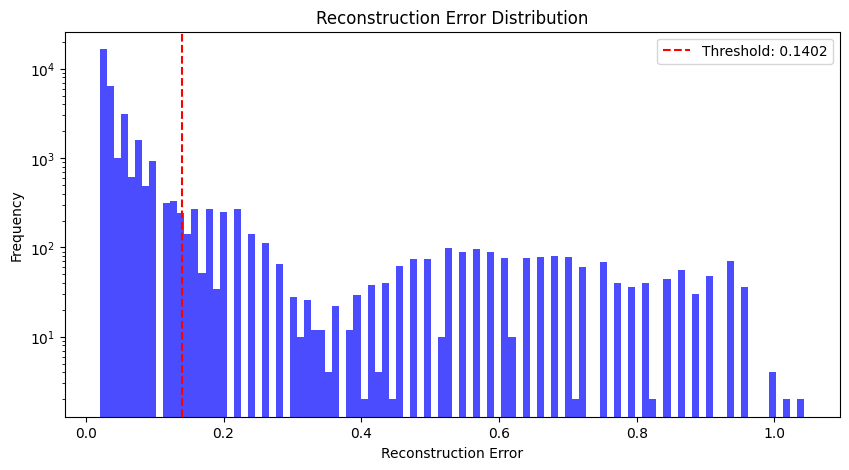

In [27]:
plt.figure(figsize=(10, 5))
plt.hist(errors, bins=100, alpha=0.7, color='blue')
plt.axvline(threshold, color='red', linestyle='--', label=f'Threshold: {threshold:.4f}')
plt.xlabel('Reconstruction Error')
plt.ylabel('Frequency')
plt.yscale("log")
plt.title('Reconstruction Error Distribution')
plt.legend()
plt.show()

In [28]:
np.max(errors)

1.0435903

Classify Anaomalies within the Dataset:

In [29]:
def is_anomaly(error, threshold):
    return error > threshold

In [30]:
anomalies = [is_anomaly(error, threshold) for error in errors]
print(np.sum(anomalies))

3474


Plot some anomalous results

In [31]:
filtered_original_data = [filename for filename, is_anomaly in zip(filenames_LC_list, anomalies) if is_anomaly]
filtered_reconstructed_data = [lc for lc, is_anomaly in zip(reconstructed_data_cpu, anomalies) if is_anomaly]

In [32]:
random_samples = random.sample(filtered_original_data,20)

In [ ]:
for filename, lc in random_samples:
    print(filename)
    plot_lc(lc, is_spectra=False)

# Clustering with PCA

The results shown are the result of clustering the anomalous Lightcurves detected by the SNR approach. NOT the entire dataset!!

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from openTSNE import TSNE
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import random
from sklearn.cluster import KMeans



## Preprocessing

Reshape:

In [46]:
X_reshaped = X.squeeze(-1)
if X_reshaped.is_cuda:
    X_reshaped = X_reshaped.cpu()
X_np = X_reshaped.numpy()

Scale:

Determine number of components to retain:

In [47]:
pca = PCA()
pca.fit(X_np)

PCA()

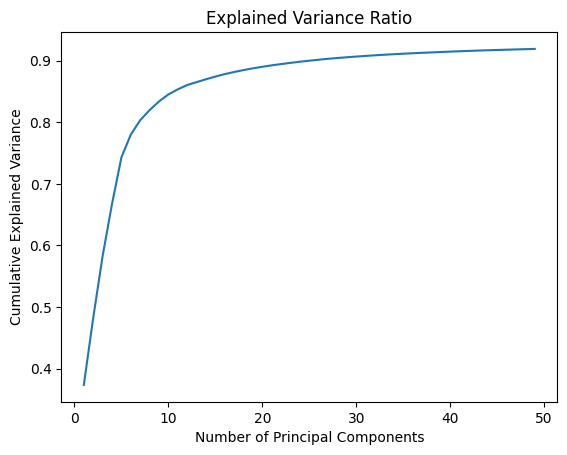

In [48]:
# Plot cumulative explained variance
explained_variance = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1, 50), explained_variance[0:49])
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance Ratio')
plt.show()

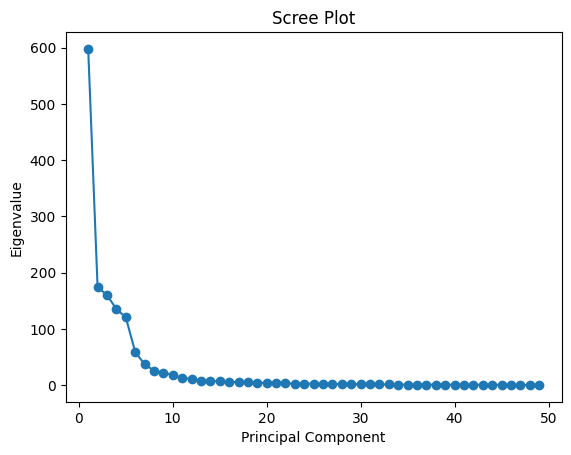

In [49]:
eigenvalues = pca.explained_variance_
plt.plot(range(1, 50), eigenvalues[0:49], marker='o')
plt.xlabel('Principal Component')
plt.ylabel('Eigenvalue')
plt.title('Scree Plot')
plt.show()

In [50]:
desired_variance_ratio = 0.95
num_components = np.argmax(explained_variance >= desired_variance_ratio) + 1
print(f"Number of components to retain {desired_variance_ratio*100}% variance: {num_components}")


Number of components to retain 95.0% variance: 213


Dimension Reduction using PCA:

In [51]:
pca = PCA(n_components=10)
data_pca = pca.fit_transform(X_np)

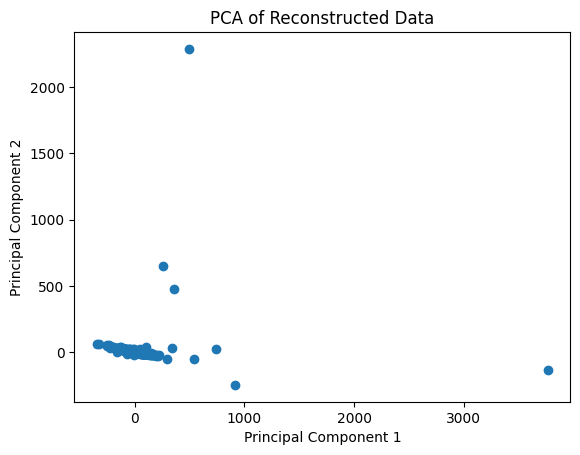

In [52]:
plt.scatter(data_pca[:, 0], data_pca[:, 1])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Reconstructed Data')
plt.show()

## Apply OpenTSNE

In [54]:
tsne = TSNE(perplexity=30, n_iter=1000, random_state=42, verbose=True, metric='euclidean')
tsne_results_pca = tsne.fit(data_pca)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, n_iter=1000, random_state=42, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 12.16 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.45 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.02 seconds
===> Running optimization with exaggeration=12.00, lr=2929.42 for 250 iterations...
Iteration   50, KL divergence 5.5902, 50 iterations in 1.7584 sec
Iteration  100, KL divergence 5.3769, 50 iterations in 1.7416 sec
Iteration  150, KL divergence 5.3840, 50 iterations in 1.7223 sec
Iteration  200, KL divergence 5.3837, 50 iterations in 1.7181 sec
Iteration  250, KL divergence 5.3837, 50 iterations in 1.7213 sec
   --> Time elapsed: 8.66 seconds
===> Running optimization with exaggerati

## Visualize the results

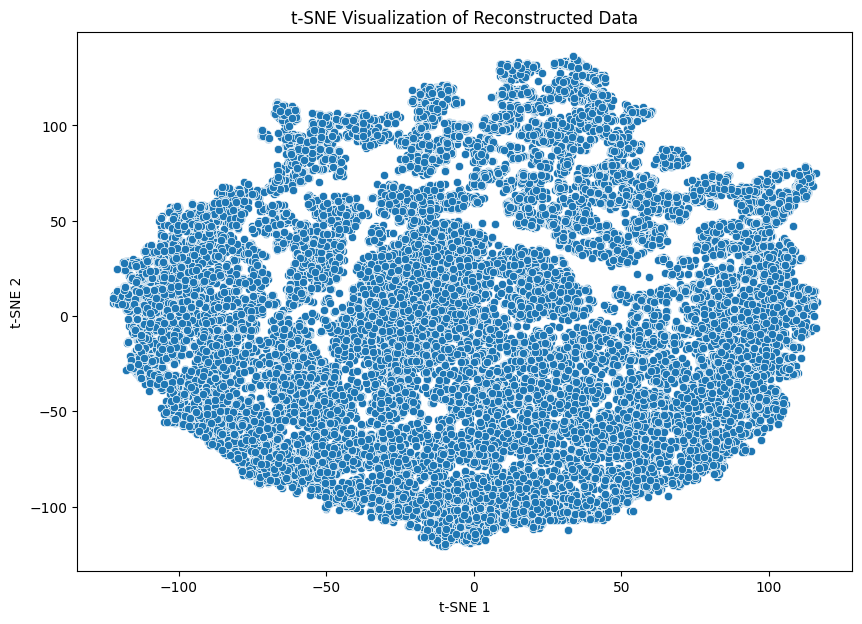

In [55]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=tsne_results_pca[:, 0], y=tsne_results_pca[:, 1])
plt.title('t-SNE Visualization of Reconstructed Data')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

## Extract Clusters

### DBSCAN

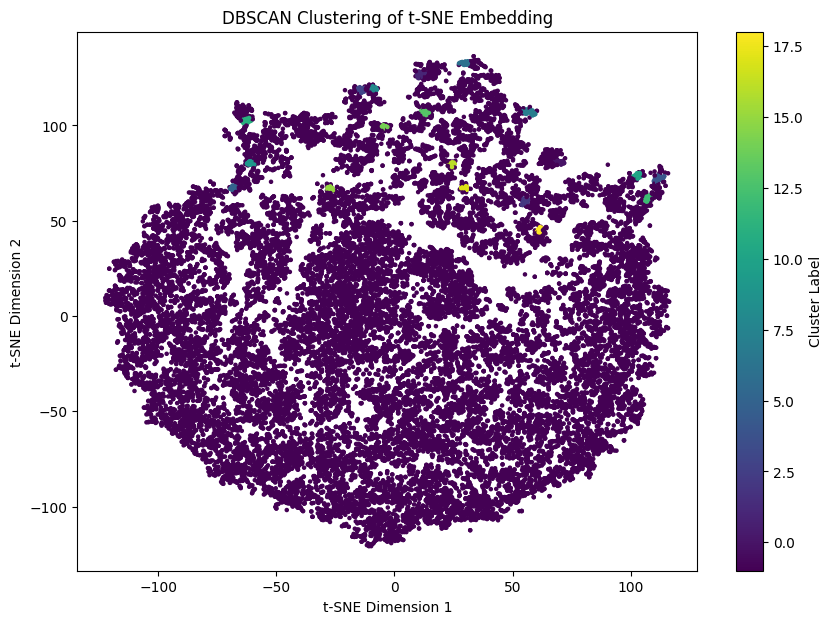

In [59]:
from sklearn.cluster import DBSCAN

# Apply DBSCAN on the t-SNE embedding
dbscan = DBSCAN(eps=1.5, min_samples=25)  # Adjust eps and min_samples for your data
clusters = dbscan.fit_predict(tsne_results_pca)

# Visualize the clustering results, where -1 represents outliers
plt.figure(figsize=(10, 7))
plt.scatter(tsne_results_pca[:, 0], tsne_results_pca[:, 1], c=clusters, cmap='viridis', s=5)
plt.title('DBSCAN Clustering of t-SNE Embedding')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.colorbar(label='Cluster Label')
plt.show()


In [46]:
# Step 1: Find unique cluster labels
unique_clusters = np.unique(clusters)

# Step 2: Create a dictionary to store light curves by cluster
clustered_light_curves = {cluster: [] for cluster in unique_clusters}

# Step 3: Populate the dictionary with light curves for each cluster
for i, cluster in enumerate(clusters):
    clustered_light_curves[cluster].append(filenames_LC_list[i])

# If you prefer lists instead of a dictionary
clustered_filenames_LC_list = [clustered_light_curves[cluster] for cluster in unique_clusters]

### Plot Random Samples from each Cluster

In [47]:
len(unique_clusters)

7

In [48]:
clustered_light_curves[-1][1][0]

'/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-01_3812_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits'

In [49]:
num_samples = 5

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-30_2508_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-2.fits


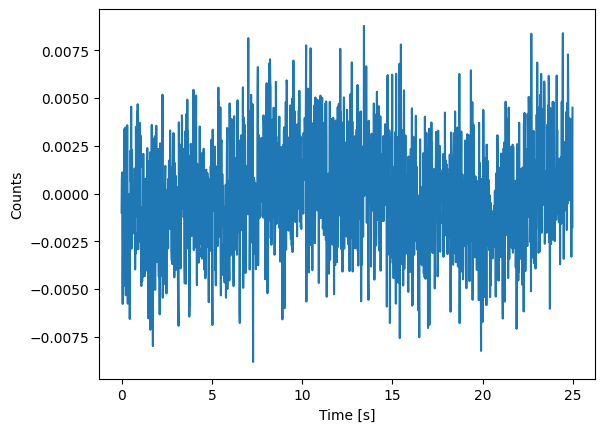

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-01-24_2953_77-21_subscan6_S20mm-SPECPOL-ARRAYDATA-2.fits


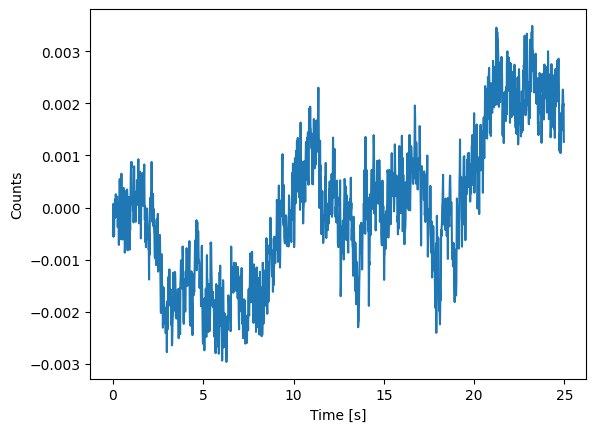

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-09-20_0224_77-21_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


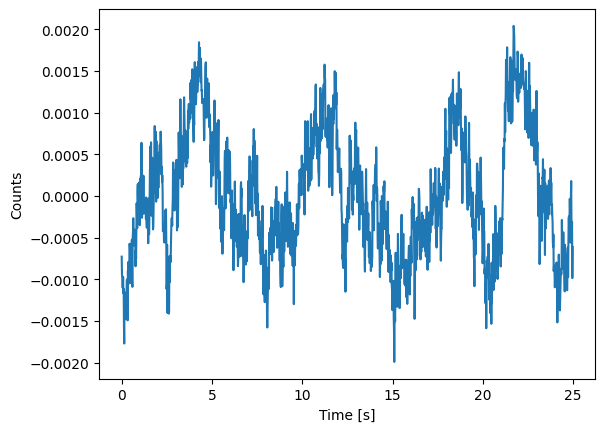

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-21_0615_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-2.fits


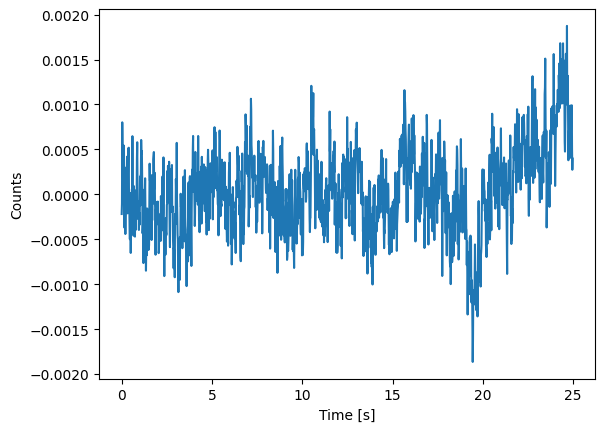

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-30_2545_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-2.fits


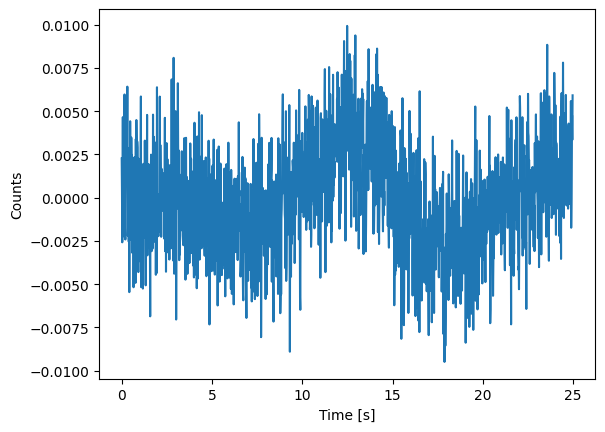

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-01_7628_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


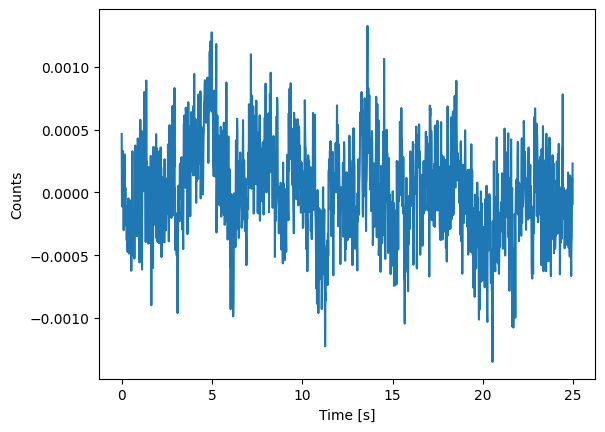

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-09-20_4874_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-2.fits


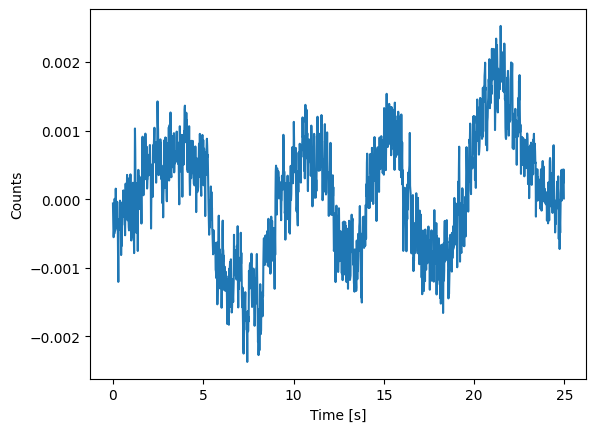

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-06-15_1937_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-2.fits


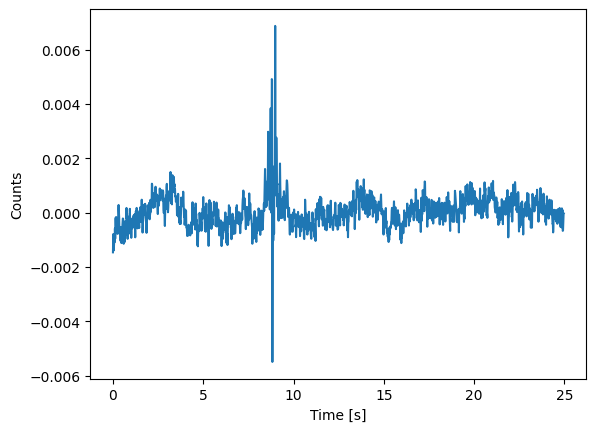

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-08-07_1046_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-2.fits


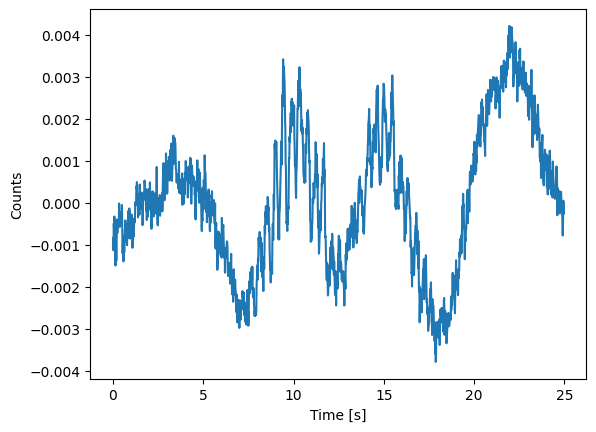

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-12-08_7830_77-21_subscan1_S20mm-SPECPOL-ARRAYDATA-2.fits


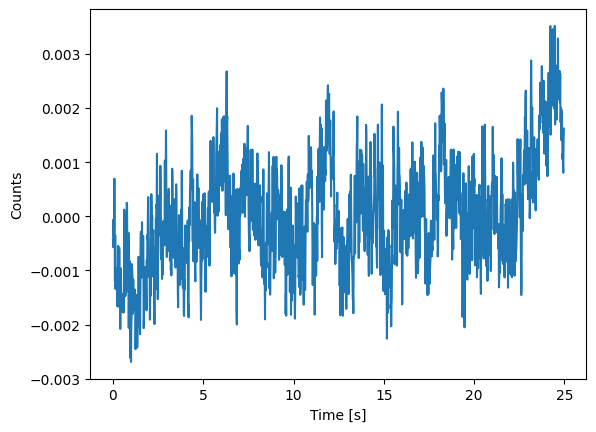

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-01-25_3038_77-21_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


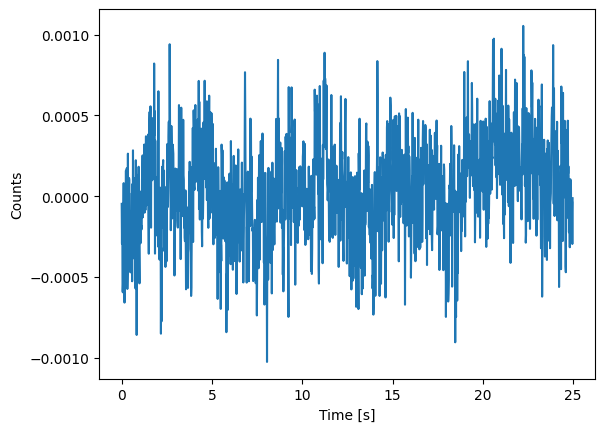

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-04-05_4314_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


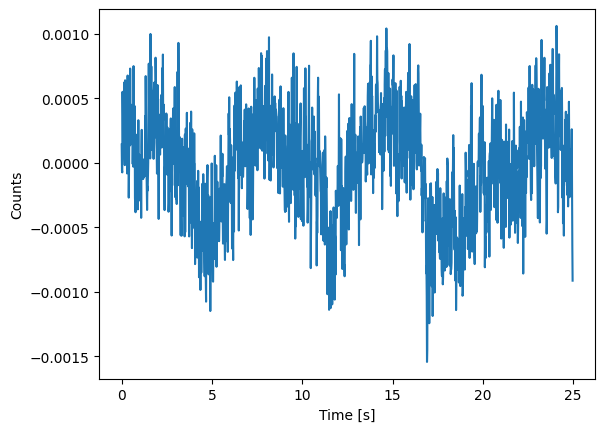

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-06-26_7525_77-21_subscan8_S20mm-SPECPOL-ARRAYDATA-1.fits


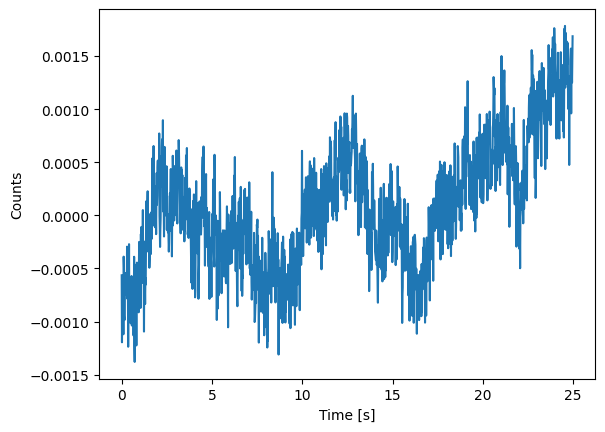

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-03-16_2084_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


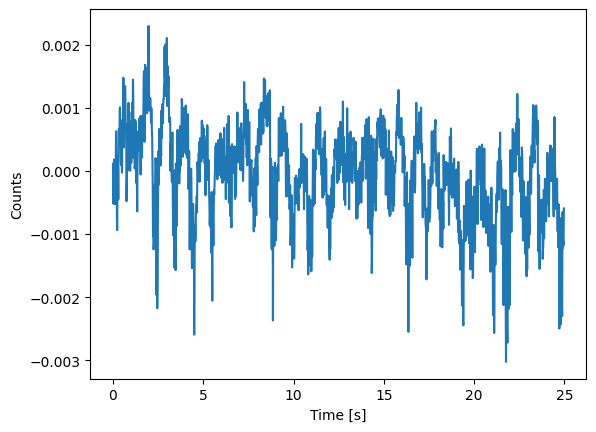

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-26_6451_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


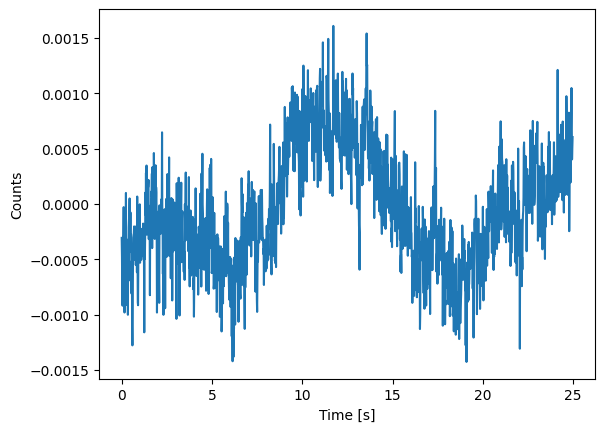

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-08-07_1248_77-21_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


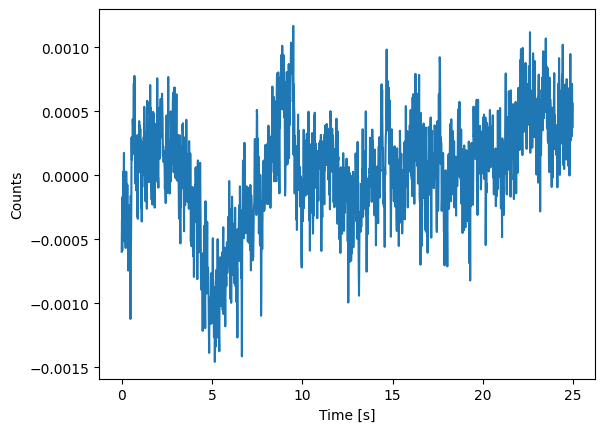

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-06-26_7498_77-21_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


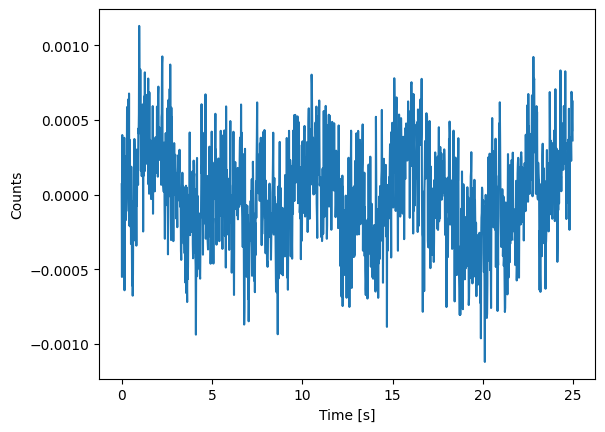

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-02-21_0533_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


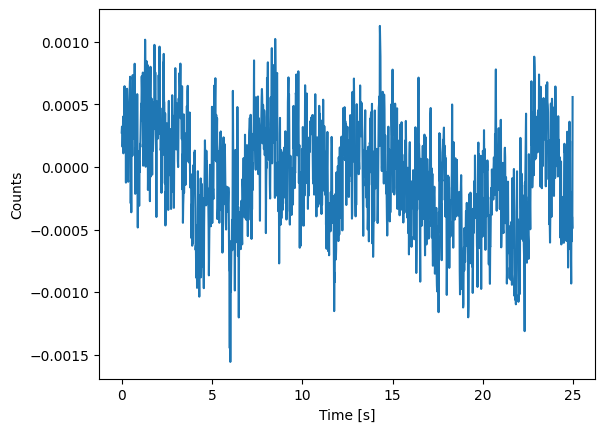

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-13_5048_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


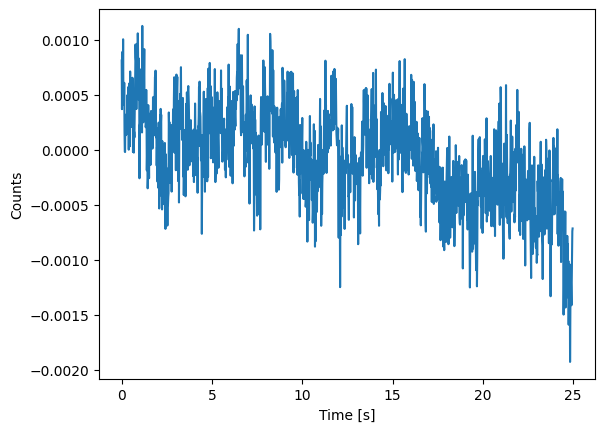

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-12-12_2854_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


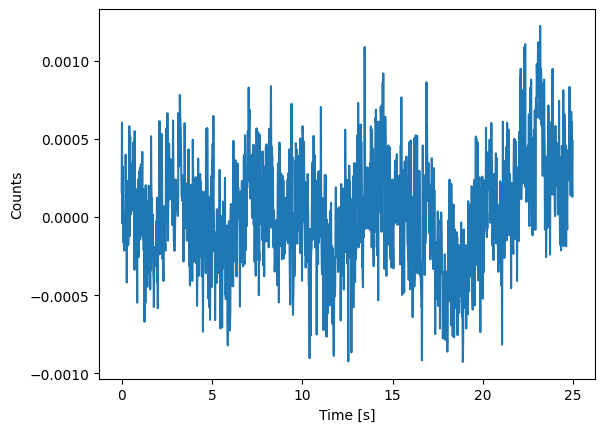

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-02-12_5286_77-21_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


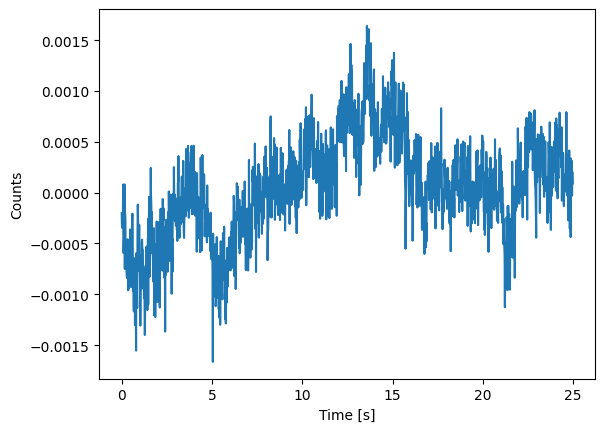

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-11-27_1382_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


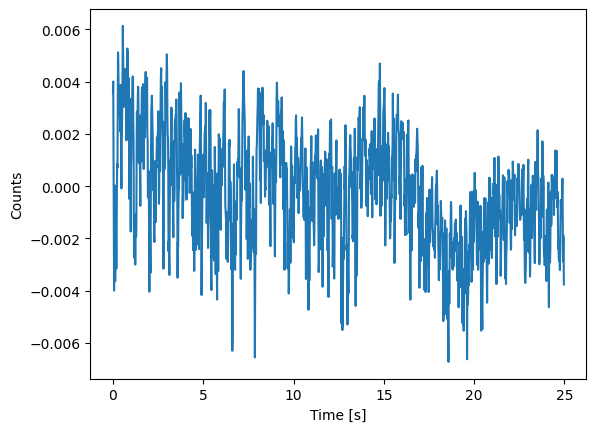

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-18_9289_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


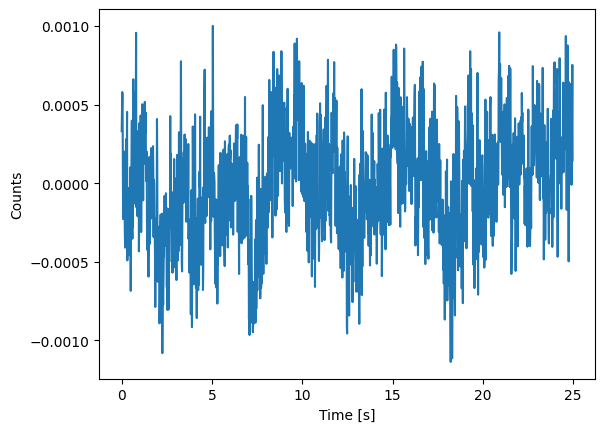

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-09-20_0211_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


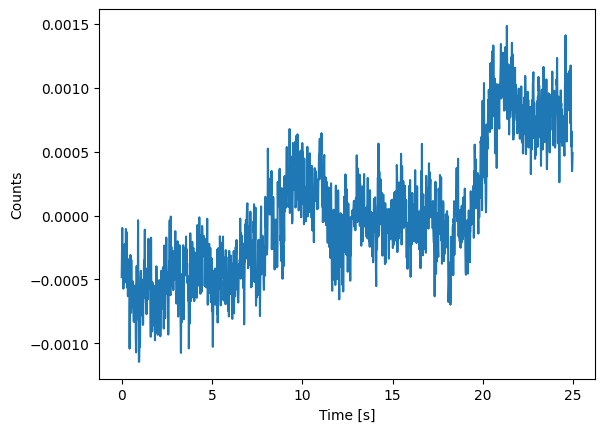

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-04-04_4184_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-2.fits


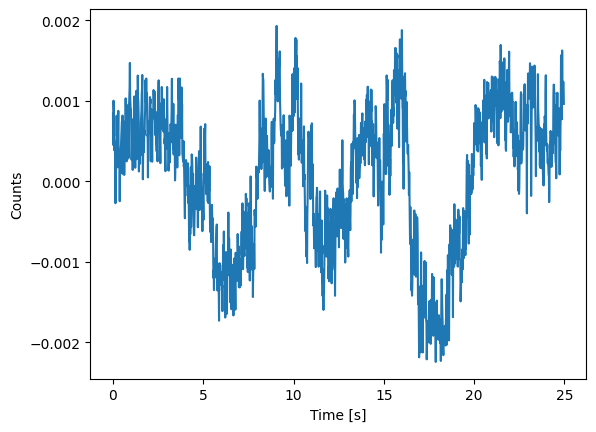

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-22_9574_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


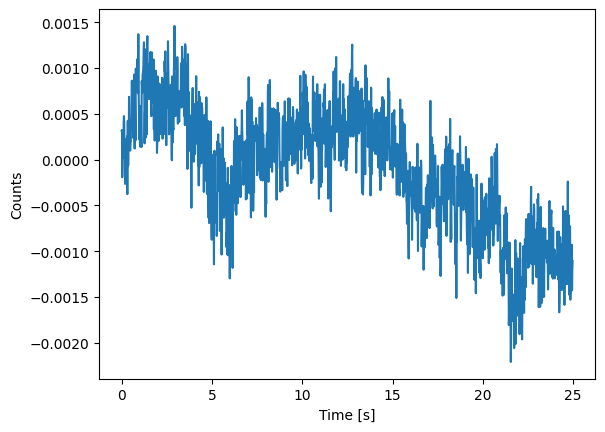

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-10_0364_77-21_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


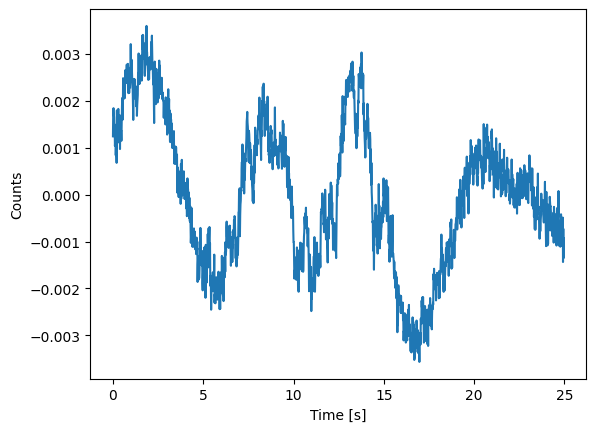

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-05-17_4501_77-21_subscan8_S20mm-SPECPOL-ARRAYDATA-1.fits


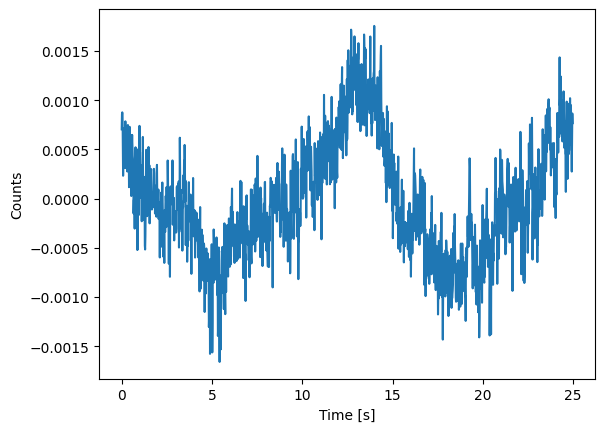

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-01-25_6896_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


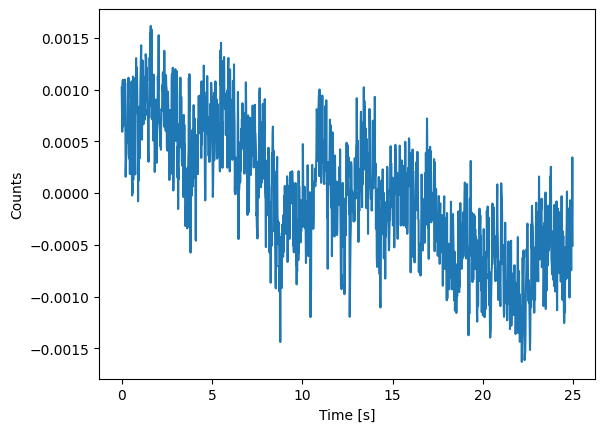

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-06-08_1433_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


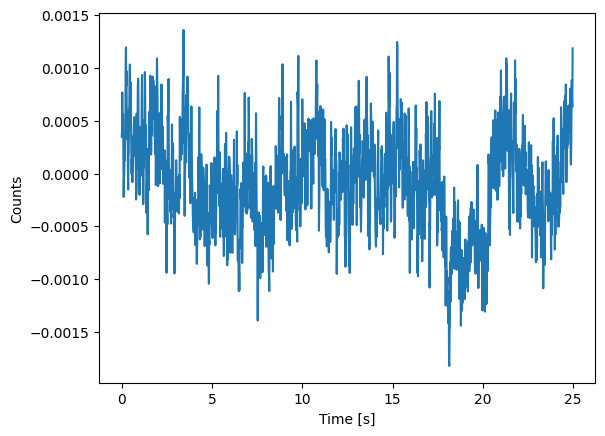

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-01-24_6826_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-1.fits


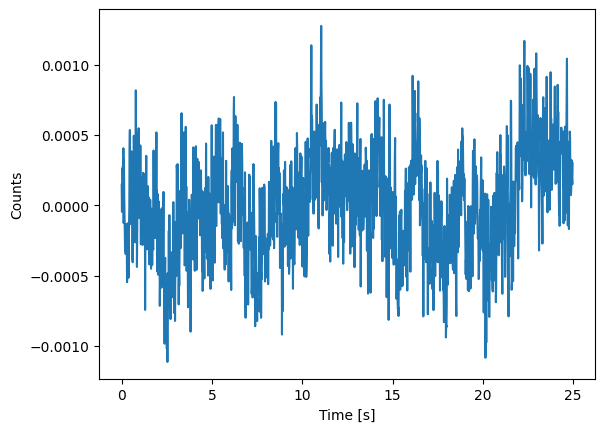

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-10-02_5696_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-2.fits


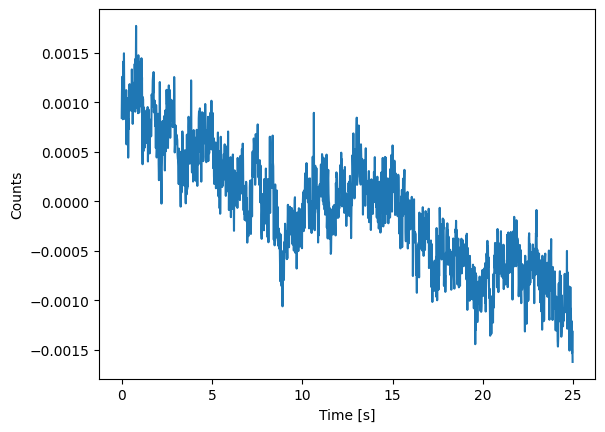

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-11-27_1457_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


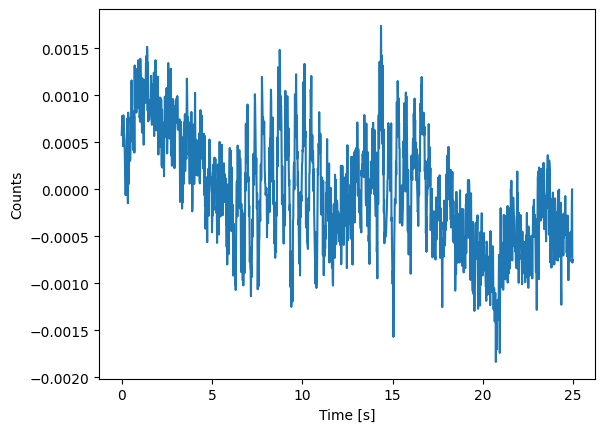

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-06-16_6457_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


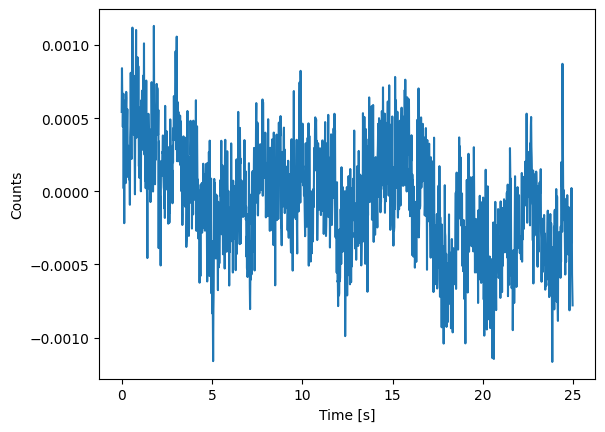

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-11-27_1470_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


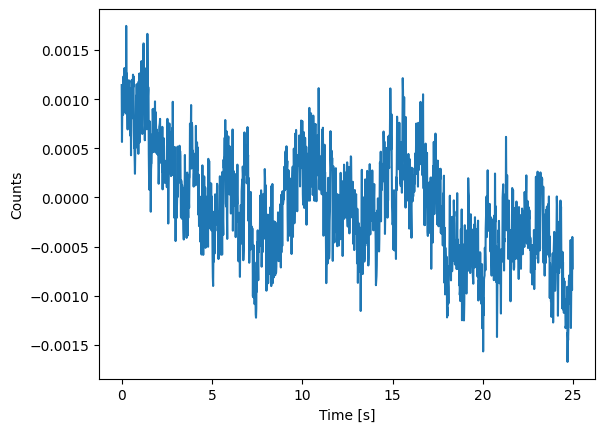

In [50]:
from IPython.display import display, HTML
for cluster_id in unique_clusters:
    clustered_light_curves_sub = clustered_light_curves[cluster]
    display(HTML(f"<h2>Cluster {cluster_id}:  There are {len(clustered_light_curves_sub)} Lightcurves in this Cluster</h2>"))
    samples = random.sample(clustered_light_curves_sub, min(num_samples, len(clustered_light_curves_sub)))

    for filename, LC in samples:
        print(filename)
        plot_lc(LC)

### K-Means

Choosing optimal number of clusters:

In [52]:
from sklearn.cluster import KMeans

inertias = []
k_values = range(2, 20)  # Try values between 2 and 20, for example

for k in tqdm(k_values):
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(tsne_results)
    inertias.append(kmeans.inertia_)

  0%|          | 0/18 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
  6%|▌         | 1/18 [00:00<00:15,  1.12it/s]/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
 11%|█         | 2/18 [00:01<00:15,  1.06it/s]/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
 17%|█▋        | 3/18 [00:02<00:14,  1.06it/s]/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will cha

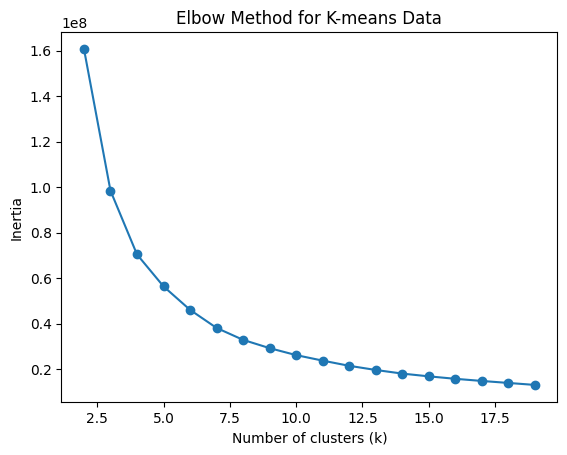

In [53]:
plt.plot(k_values, inertias, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-means Data")
plt.show()

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


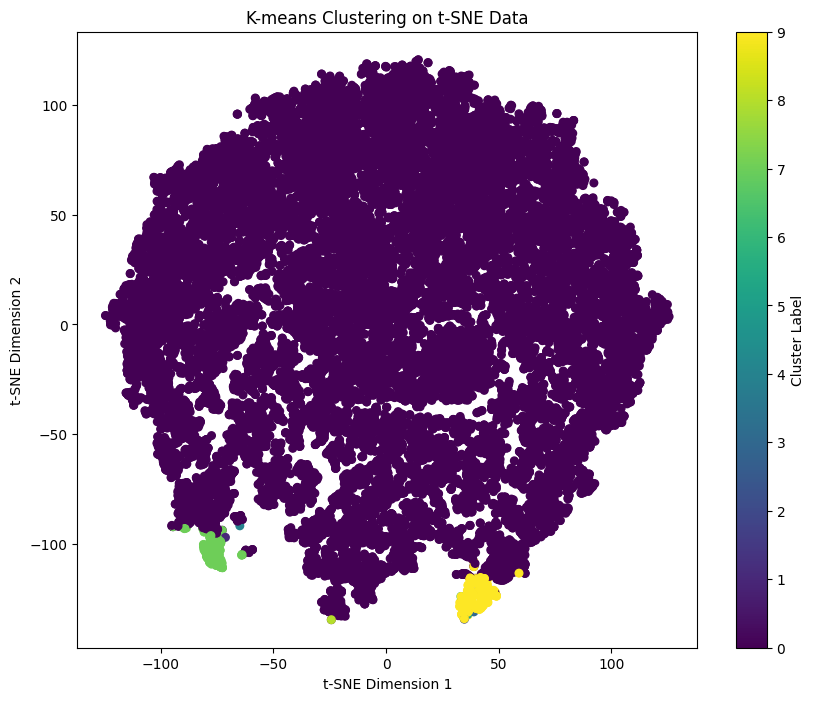

In [54]:
k = 10  # Example number of clusters; adjust based on your needs
kmeans = KMeans(n_clusters=k, random_state=0)
kmeans_labels = kmeans.fit_predict(tsne_results_pca)

# Plotting the results
plt.figure(figsize=(10, 8))
plt.scatter(tsne_results_pca[:, 0], tsne_results_pca[:, 1], c=kmeans_labels, cmap='viridis', s=30)
plt.colorbar(label="Cluster Label")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("K-means Clustering on t-SNE Data")
plt.show()

plotting random samples from each cluster:

In [55]:
# Step 1: Find unique cluster labels from K-means
unique_clusters = np.unique(kmeans_labels)

# Step 2: Create a dictionary to store light curves by cluster
clustered_light_curves = {cluster: [] for cluster in unique_clusters}

# Step 3: Populate the dictionary with light curves for each cluster
for i, cluster in enumerate(kmeans_labels):
    clustered_light_curves[cluster].append(filenames_LC_list[i])

# Convert the dictionary to a list of clusters for easier iteration (optional)
clustered_filenames_LC_list = [clustered_light_curves[cluster] for cluster in unique_clusters]

In [56]:
# Parameters
num_samples = 5  # Number of random samples per cluster

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-09-30_5677_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-2.fits


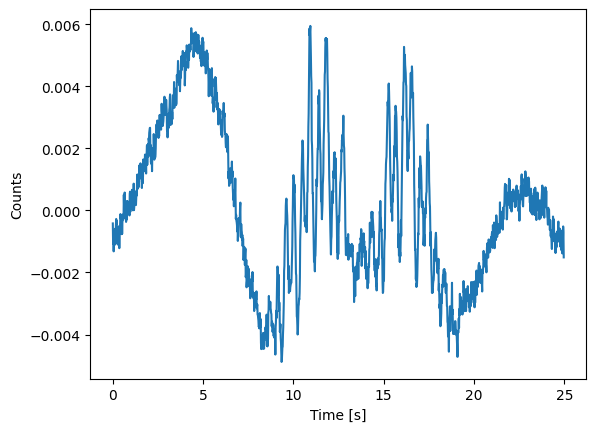

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-05-29_5474_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


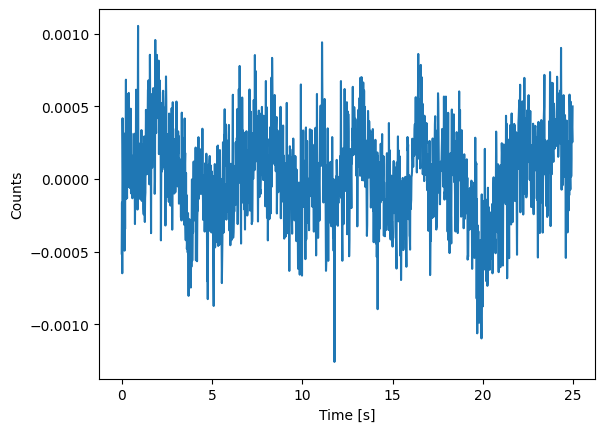

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-11-18_5775_81-20_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


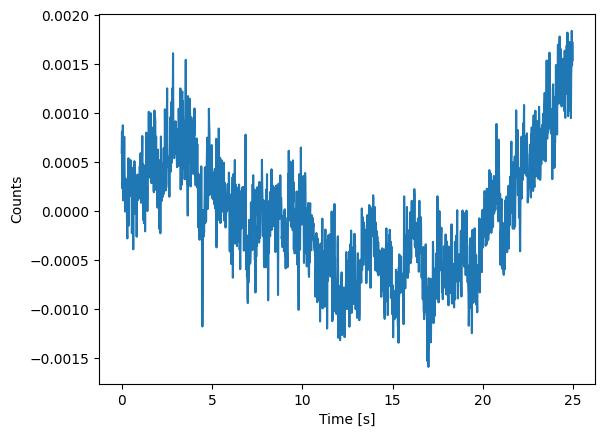

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-30_2607_77-21_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


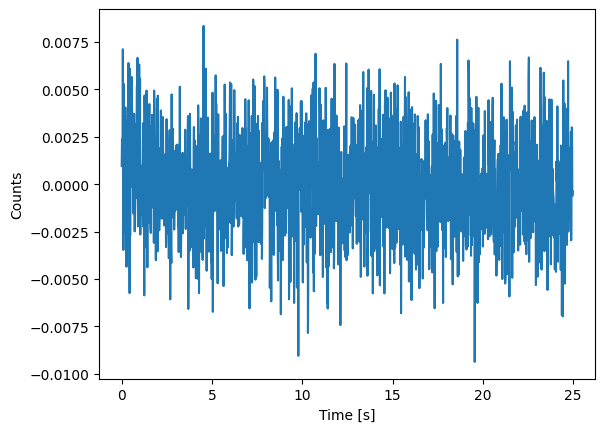

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-10-24_3786_77-21_subscan3_S20mm-SPECPOL-ARRAYDATA-2.fits


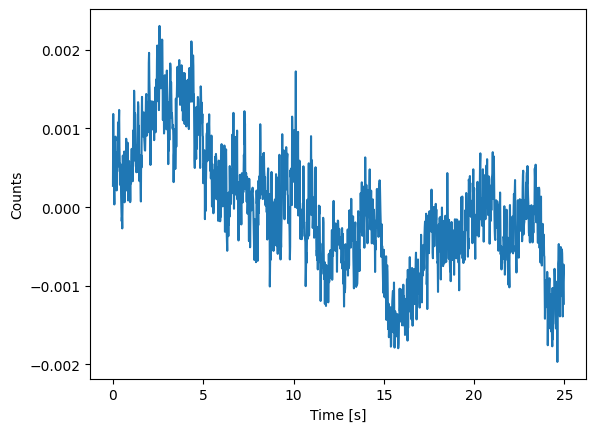

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-10-07_2378_77-21_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


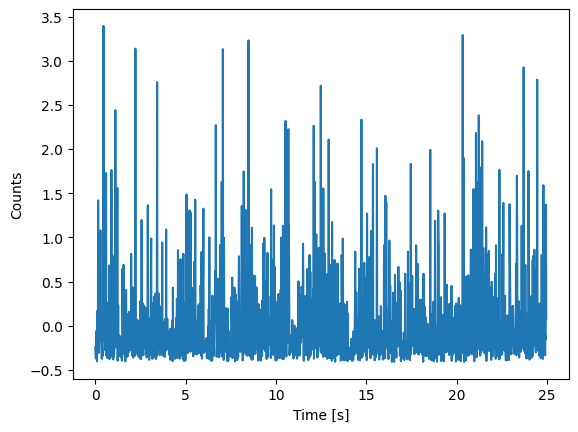

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-12-08_7781_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


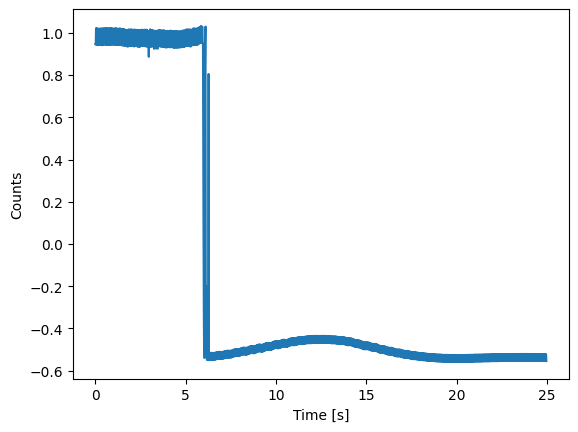

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-10-07_2378_77-21_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


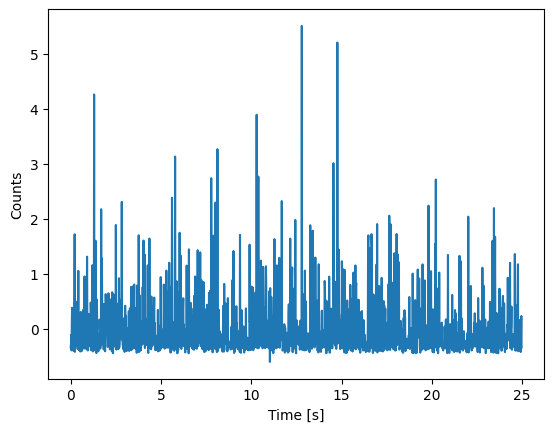

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-10-07_2378_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


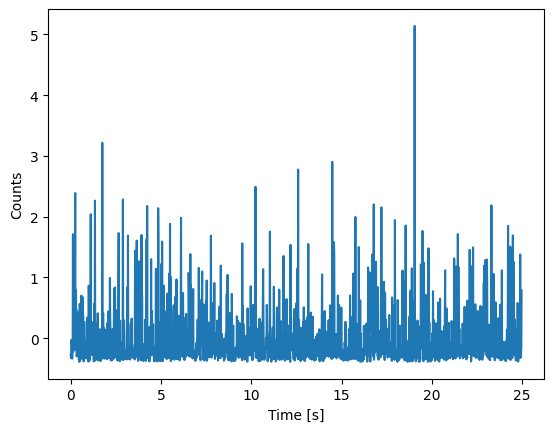

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-05-02_2961_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-2.fits


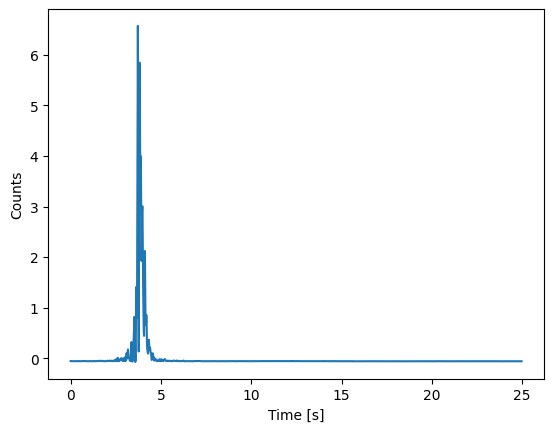

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-05-18_4572_77-21_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


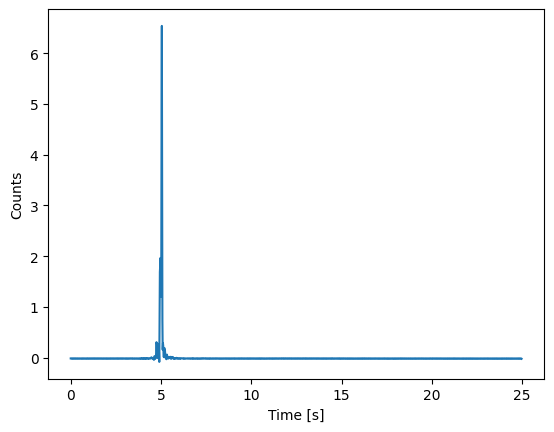

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-01_3770_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-2.fits


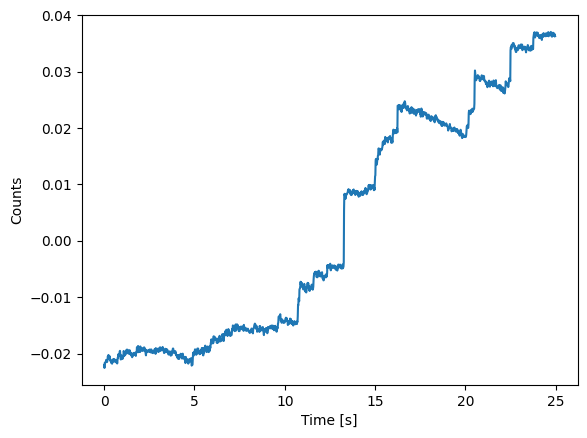

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-10_0259_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-2.fits


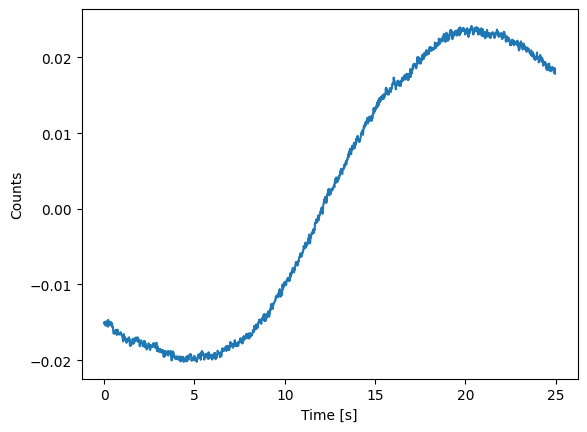

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-07-10_9009_77-21_subscan2_S20mm-SPECPOL-ARRAYDATA-2.fits


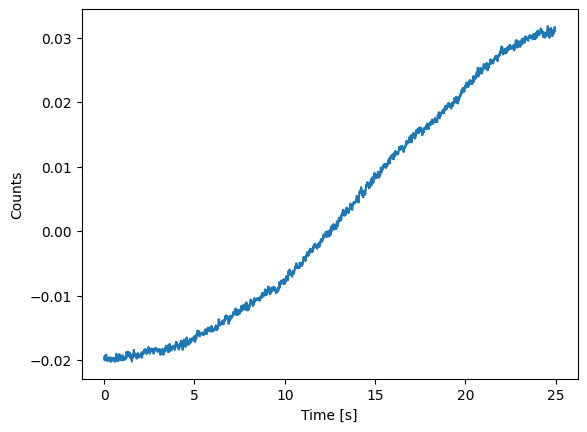

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2021-11-23_6196_77-21_subscan8_S20mm-SPECPOL-ARRAYDATA-1.fits


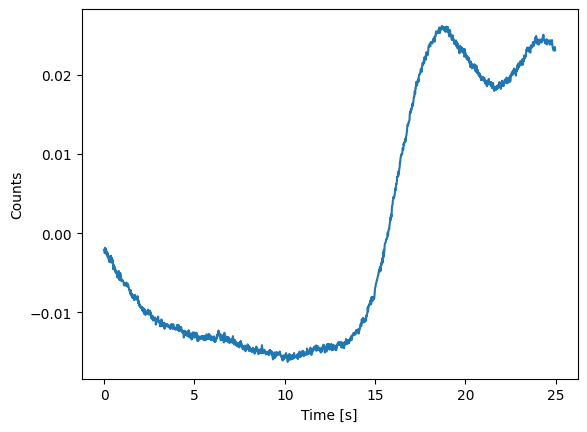

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-09-19_4769_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


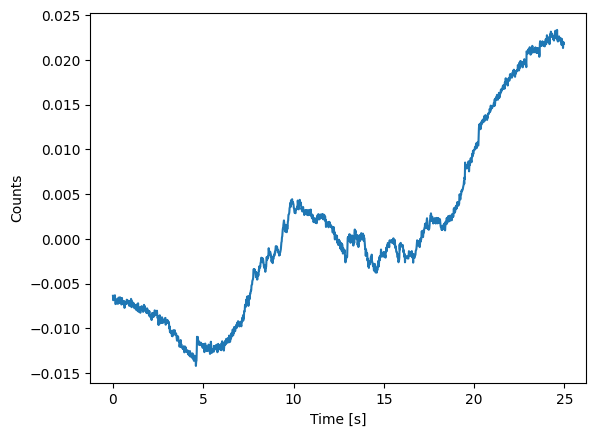

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-08-22_2238_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-2.fits


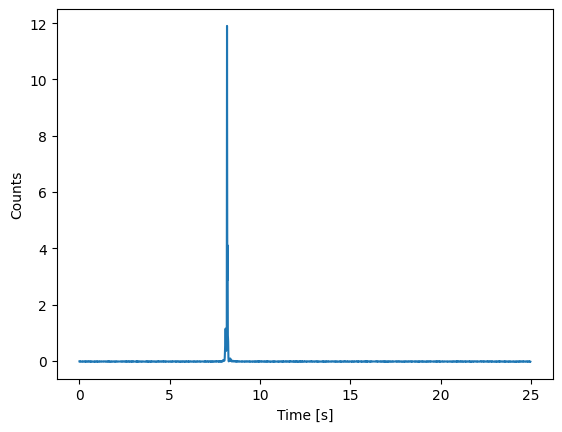

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-07-01_3813_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-2.fits


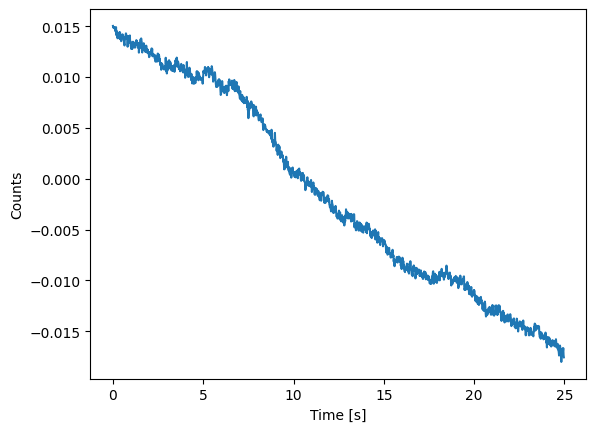

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-05-02_7842_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-2.fits


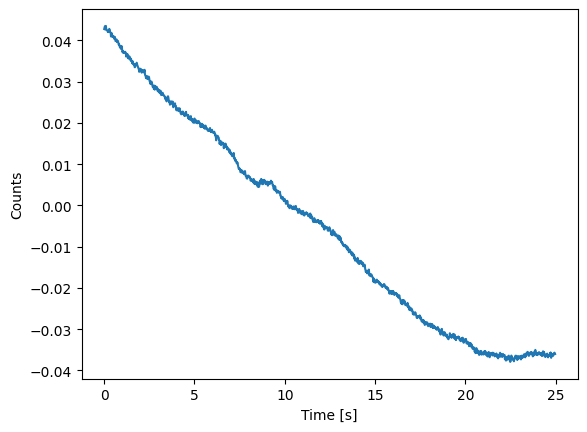

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-09_0107_77-21_subscan7_S20mm-SPECPOL-ARRAYDATA-2.fits


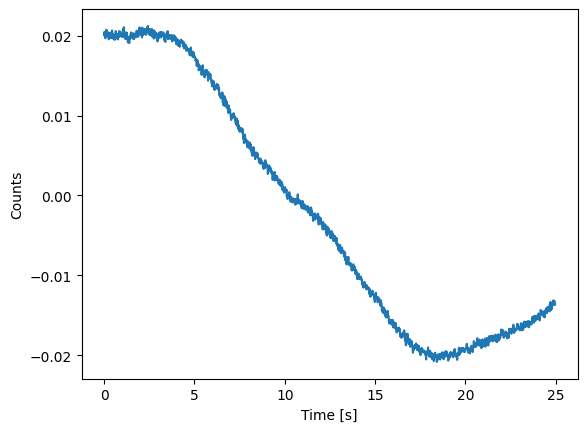

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-01-30_7654_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


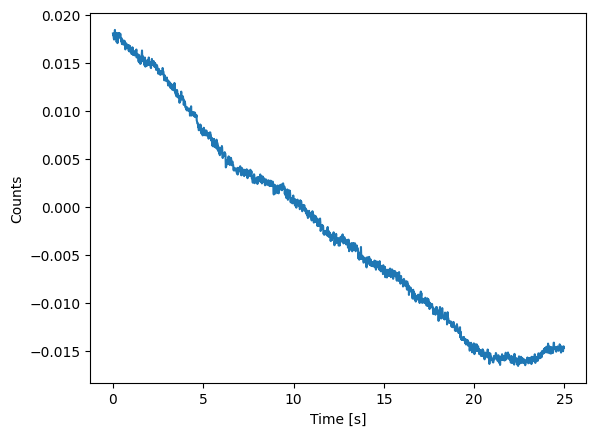

Filename: /workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-01-30_7708_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-2.fits


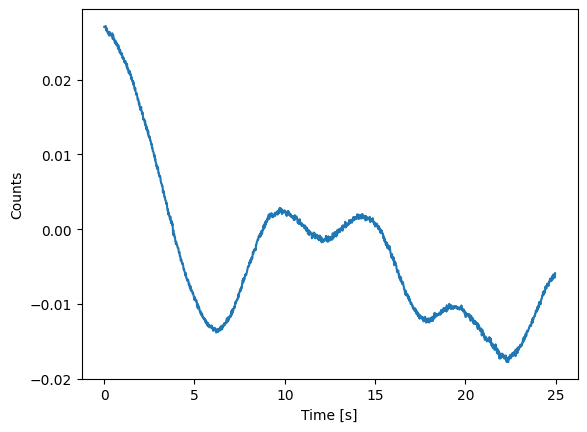

In [57]:
# Step 4: Iterate over each cluster and plot random samples
for cluster_id, filenames_LC_sublist in enumerate(clustered_filenames_LC_list):
    display(HTML(f"<h2>Cluster {cluster_id}: There are {len(filenames_LC_sublist)} Lightcurves in this Cluster</h2>"))
    
    # Step 5: Randomly select a subset of light curves from this cluster
    samples = random.sample(filenames_LC_sublist, min(num_samples, len(filenames_LC_sublist)))
    
    # Step 6: Plot each selected light curve
    for filename, LC in samples:
        print(f"Filename: {filename}")
        plot_lc(LC)  # Plot the light curve using your custom plot function

# Three more Anomaly Detection Approaches

<a id='pca-cell'></a>
## PCA with reconstruction

Each lightvurve will be treated as one dimension. PCA is then used to reduce those ~35000 dimensions to just 1 dimension, which is then being reconstructed to the original dimensions. The error between the reconstructed lightcurves and the original lightcurves determines how anomalous a lightcurve may be. A treshold is set to filter out the most anomalous lightcurves.

In [64]:
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

Reshape:

In [65]:
X_reshaped = X.squeeze(-1)
if X_reshaped.is_cuda:
    X_reshaped = X_reshaped.cpu()
X_np = X_reshaped.numpy()

Determine number of components to retain:

In [66]:
pca = PCA()
pca.fit(X_np)

PCA()

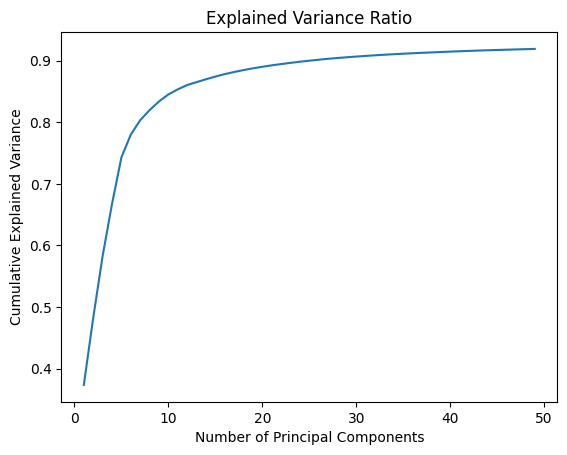

In [67]:
# Plot cumulative explained variance
explained_variance = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1, 50), explained_variance[0:49])
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance Ratio')
plt.show()

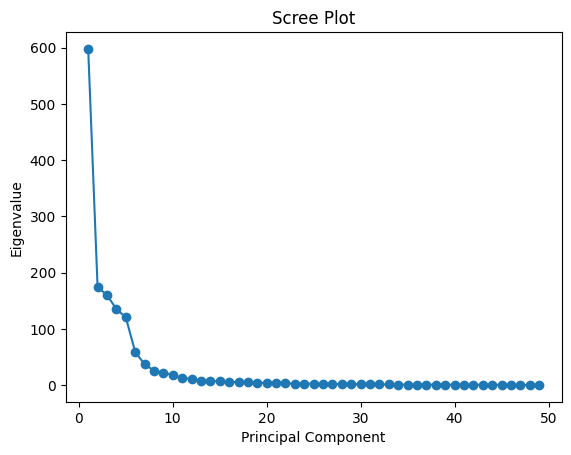

In [68]:
eigenvalues = pca.explained_variance_
plt.plot(range(1, 50), eigenvalues[0:49], marker='o')
plt.xlabel('Principal Component')
plt.ylabel('Eigenvalue')
plt.title('Scree Plot')
plt.show()

In [69]:
desired_variance_ratio = 0.95
num_components = np.argmax(explained_variance >= desired_variance_ratio) + 1
print(f"Number of components to retain {desired_variance_ratio*100}% variance: {num_components}")


Number of components to retain 95.0% variance: 213


Dimension Reduction using PCA:

In [70]:
pca = PCA(n_components=1)
X_pca = pca.fit_transform(X_np)

Reconstruct Lightcurves:

In [71]:
X_reconstructed = pca.inverse_transform(X_pca)

Calculate Reconstruction Error:

In [216]:
reconstruction_errors = np.mean((X_np - X_reconstructed) ** 2, axis=1)
threshold = np.percentile(reconstruction_errors, 95)

In [218]:
pcaError_filename_lc_list = [(error, filename, lightcurve) for error, (filename, lightcurve) in zip(reconstruction_errors, filenames_LC_list)]
sorted_list_pca = sorted(pcaError_filename_lc_list, key=lambda x: x[0], reverse=True)

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8376_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-1.fits


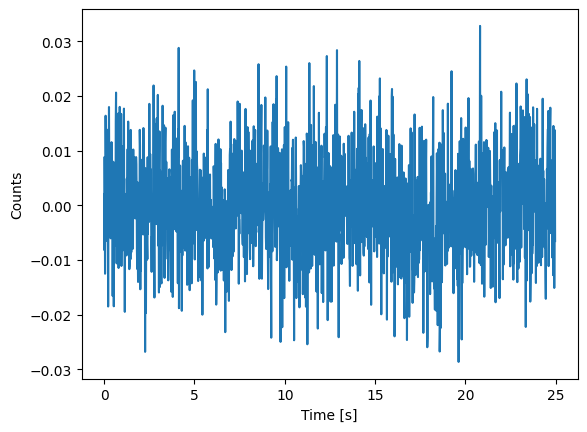

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8358_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


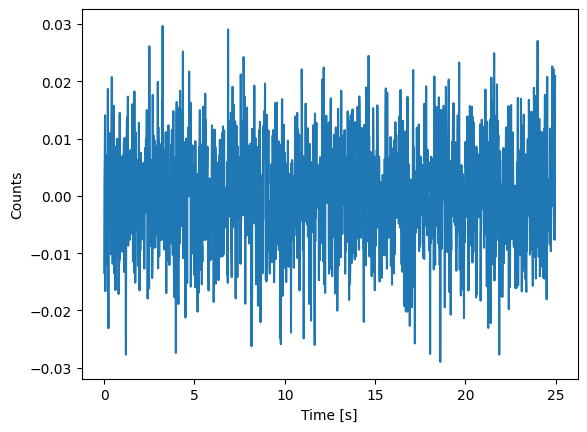

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8358_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


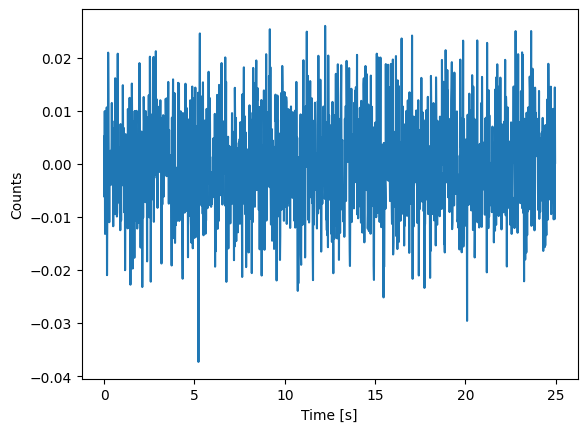

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8409_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


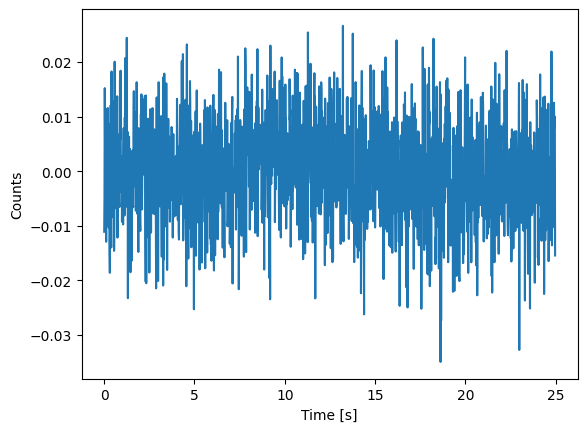

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-10-14_6929_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


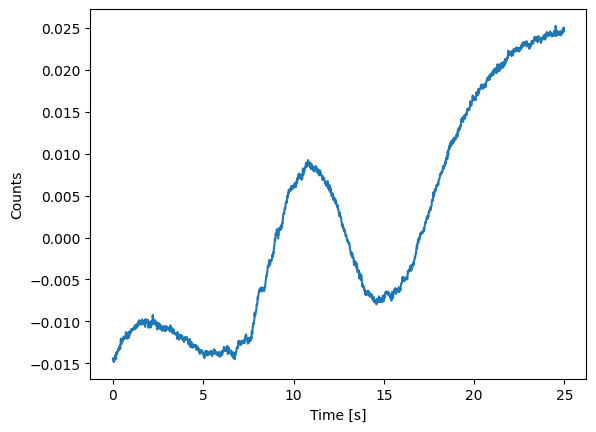

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8346_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


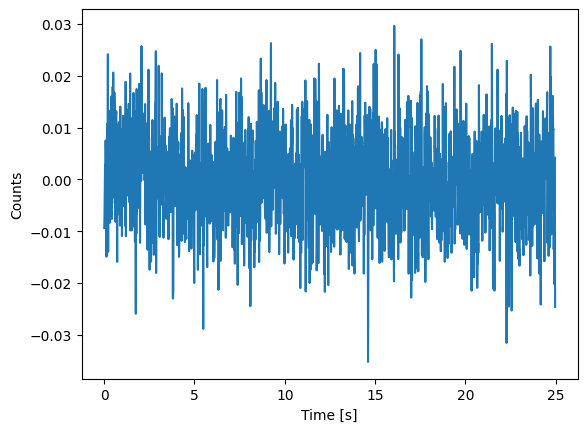

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-08-29_2880_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


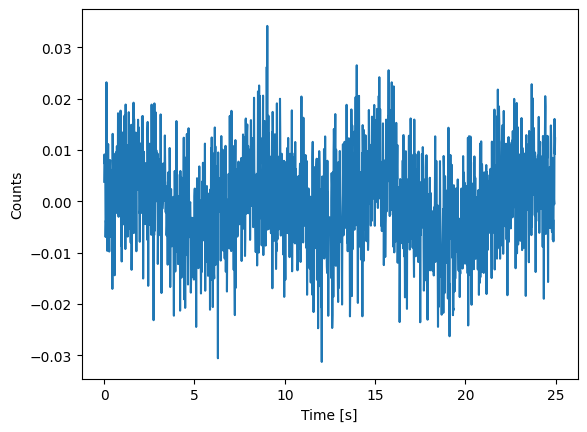

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-07-09_8728_77-21_subscan8_S20mm-SPECPOL-ARRAYDATA-2.fits


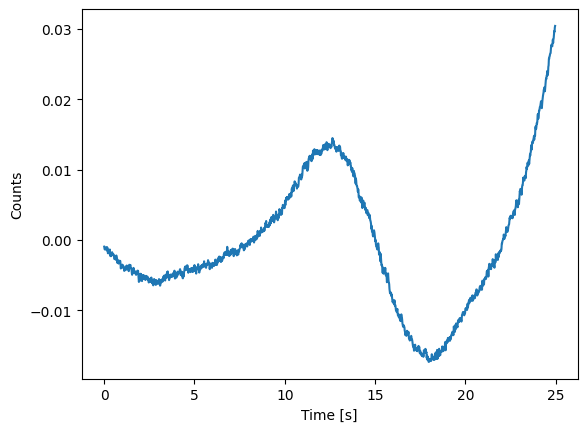

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-07-09_8728_77-21_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


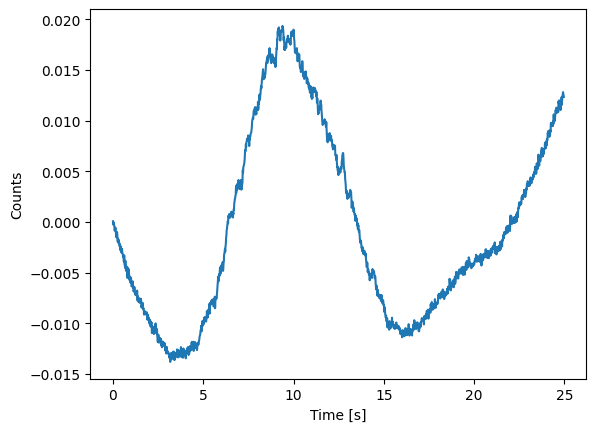

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8414_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


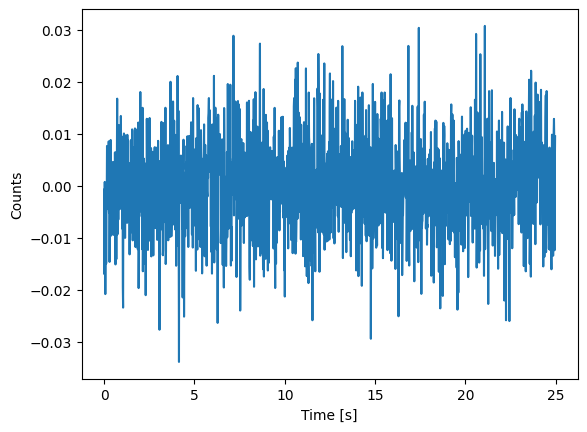

In [221]:
for error, filename, lc in sorted_list_pca[450:460]:
    print(filename)
    plot_lc(lc)
    #/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-11-27_1476_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


# Isolation Forest

In [45]:
from sklearn.ensemble import IsolationForest
from scipy.ndimage import uniform_filter1d

In [46]:
X_np = X.squeeze(-1).numpy()  # Squeeze out the last dimension to get shape (35153, 1600)

In [47]:
# Initialize the IsolationForest model
iso_forest = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1, verbose=1, bootstrap=True)

# Fit the model on the light curves data
iso_forest.fit(X_np)

# Compute anomaly scores
anomaly_scores = iso_forest.decision_function(X_np)

[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 out of  24 | elapsed:    0.2s remaining:    2.7s
[Parallel(n_jobs=24)]: Done  24 out of  24 | elapsed:    0.3s finished


In [48]:
# Sort indices based on scores (smallest to largest)
sorted_indices = np.argsort(anomaly_scores)
sorted_scores = anomaly_scores[sorted_indices]

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


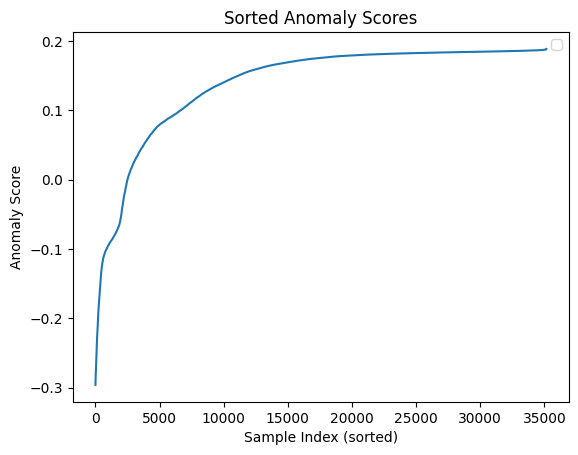

In [49]:
import matplotlib.pyplot as plt

plt.plot(sorted_scores)
plt.xlabel('Sample Index (sorted)')
plt.ylabel('Anomaly Score')
plt.title('Sorted Anomaly Scores')
plt.legend()
plt.show()

In [105]:
isoError_filename_lc_list = [(error, filename, lightcurve) for error, (filename, lightcurve) in zip(anomaly_scores, filenames_LC_list)]
sorted_list_iso = sorted(isoError_filename_lc_list, key=lambda x: x[0])

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-30_2480_77-21_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


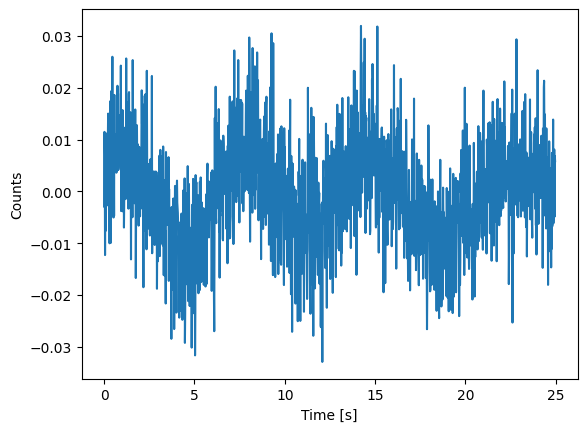

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-06-08_1438_82-22_subscan7_S20mm-SPECPOL-ARRAYDATA-1.fits


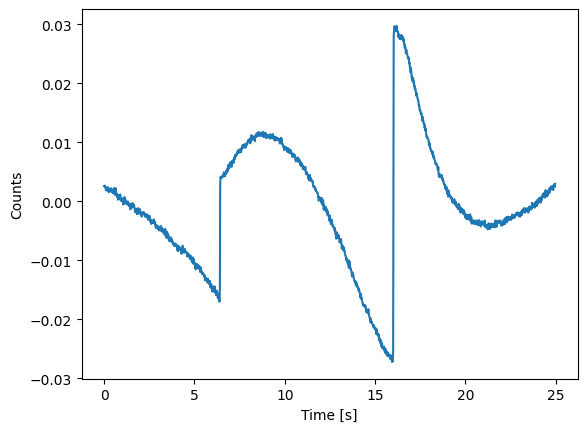

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-04-13_5302_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-2.fits


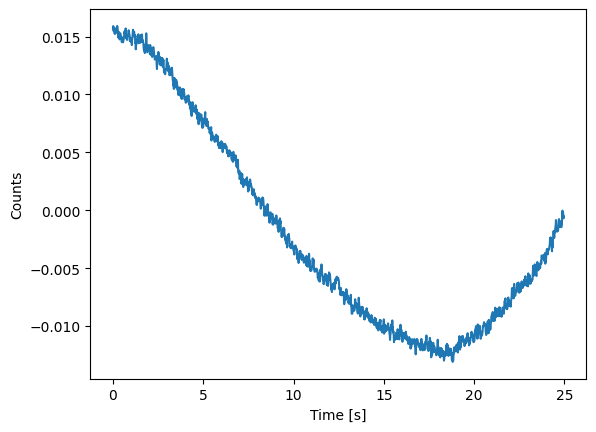

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-30_2498_77-21_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


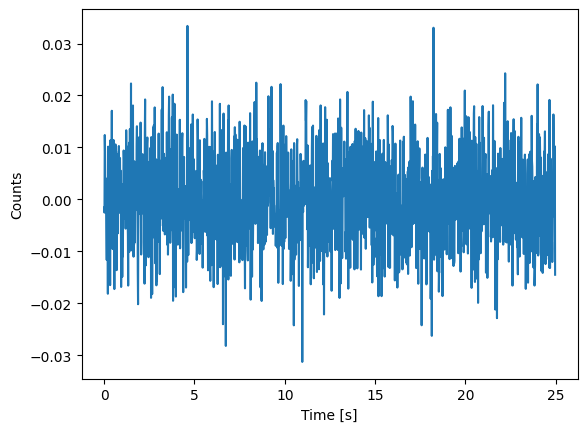

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-07-28_0187_77-21_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


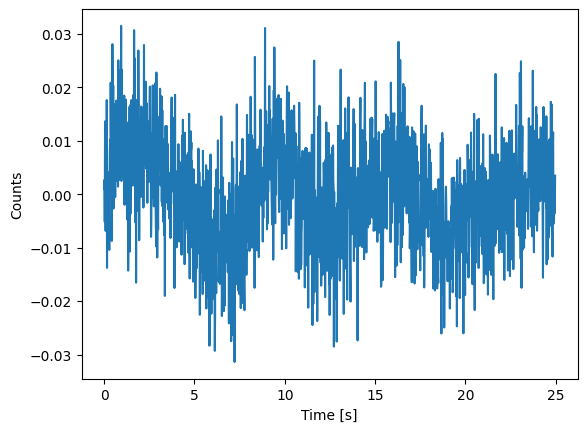

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-11-03_8970_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


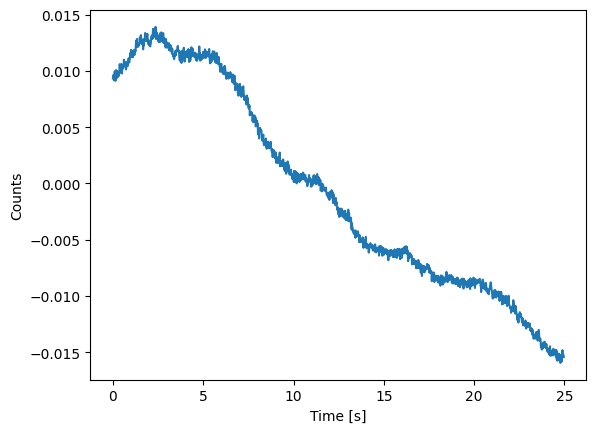

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-07-09_8739_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-2.fits


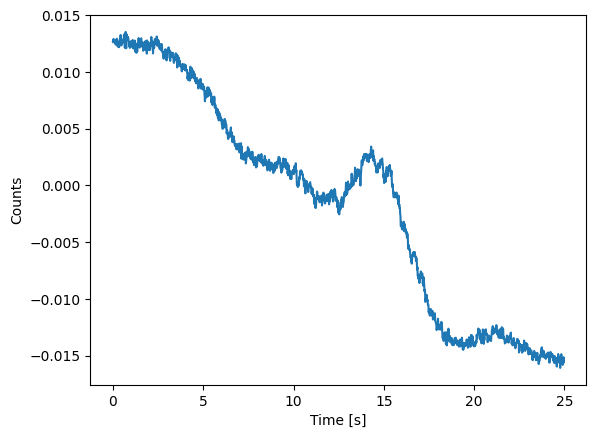

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8358_82-22_subscan8_S20mm-SPECPOL-ARRAYDATA-1.fits


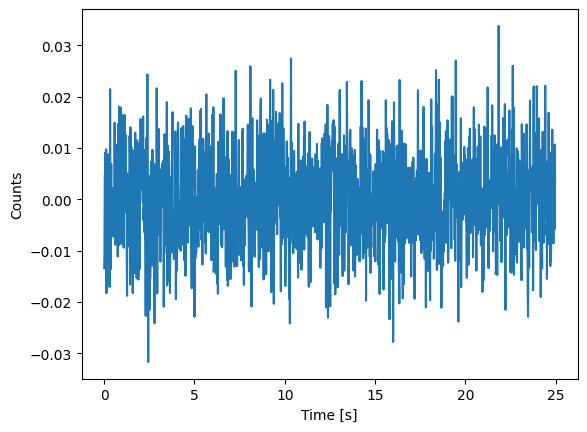

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-07-25_9967_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


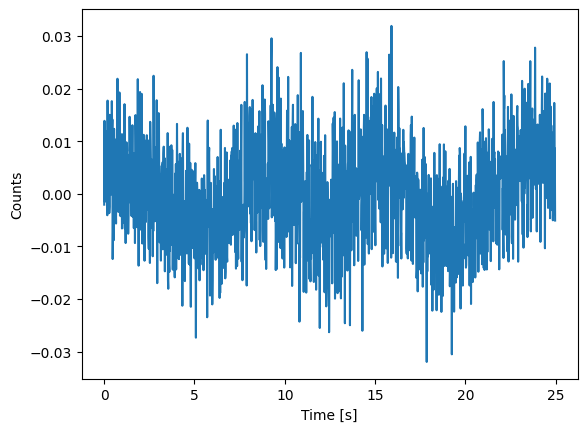

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-06-08_1438_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-2.fits


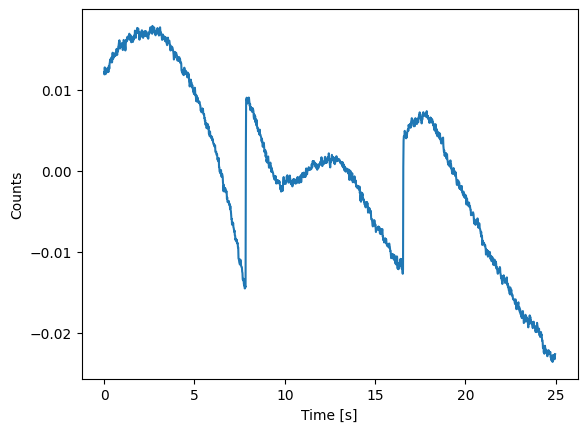

In [113]:
for o_lc in sorted_list_iso[530:540]:  # Plot 5 random light curves from the cluster
    _, filename, lc = o_lc
    print(f'{filename}')
    plot_lc(lc)


# One Class SVM

In [125]:
from sklearn.svm import OneClassSVM

In [126]:
X_np = X.squeeze(-1).numpy()  # Squeeze out the last dimension to get shape (35153, 1600)

Train the model:

In [209]:
# Initialize the model
oc_svm = OneClassSVM(gamma='auto', nu=0.1, verbose=1)  # Adjust `nu` and `gamma` as needed

# Fit the model
oc_svm.fit(X_np)

[LibSVM]...
*
optimization finished, #iter = 3206
obj = 667692.912914, rho = 776.695041
nSV = 3519, nBSV = 3514


OneClassSVM(gamma='auto', nu=0.1, verbose=1)

Predict Anomalies:

In [210]:
anomaly_scores = oc_svm.decision_function(X_np)

Analyze Result:

In [204]:
# Sort indices based on scores (smallest to largest)
sorted_indices = np.argsort(anomaly_scores)
sorted_scores = anomaly_scores[sorted_indices]

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


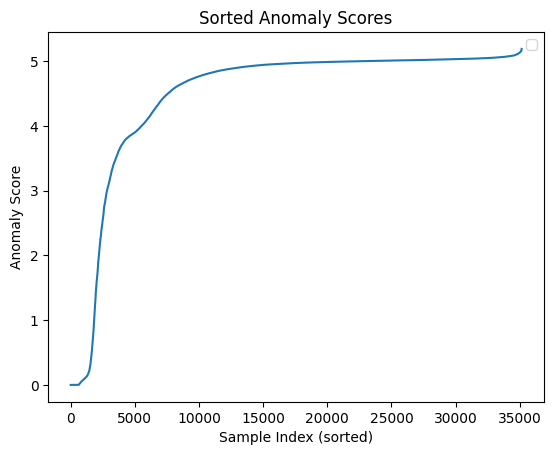

In [205]:
import matplotlib.pyplot as plt

plt.plot(sorted_scores)
plt.xlabel('Sample Index (sorted)')
plt.ylabel('Anomaly Score')
plt.title('Sorted Anomaly Scores')
plt.legend()
plt.show()

In [212]:
ocsvmError_filename_lc_list = [(error, filename, lightcurve) for error, (filename, lightcurve) in zip(anomaly_scores, filenames_LC_list)]
sorted_list_ocsvm = sorted(ocsvmError_filename_lc_list, key=lambda x: x[0])

In [ ]:
with open('/workspace/data/TELAMON_data/results/OCSVM.pkl', 'wb') as file:
    pickle.dump(sorted_list_ocsvm, file)    

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8398_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


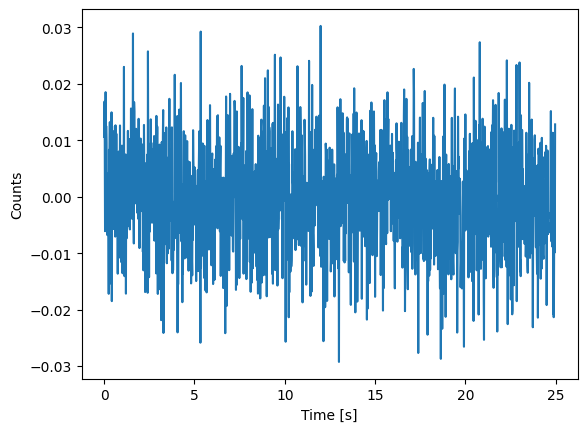

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-03-16_2092_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


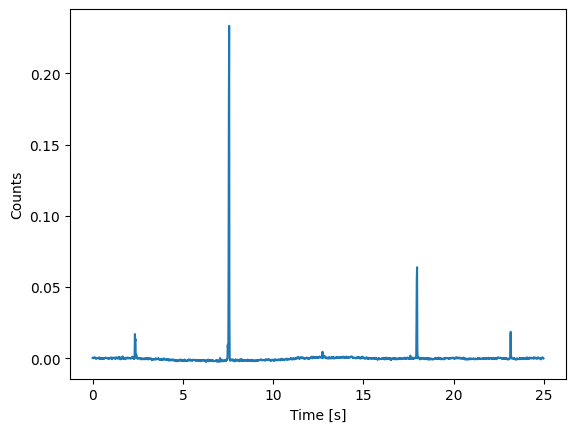

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8367_82-22_subscan1_S20mm-SPECPOL-ARRAYDATA-1.fits


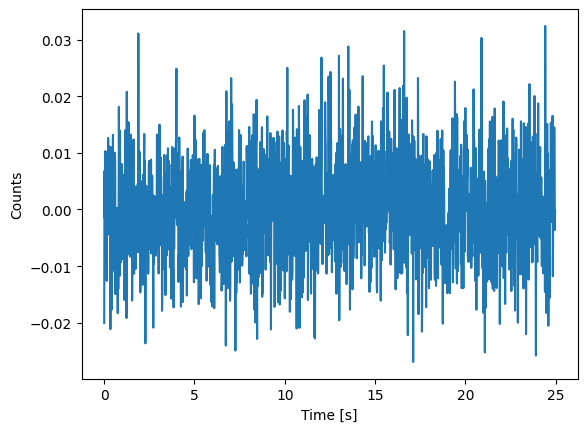

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8413_82-22_subscan2_S20mm-SPECPOL-ARRAYDATA-1.fits


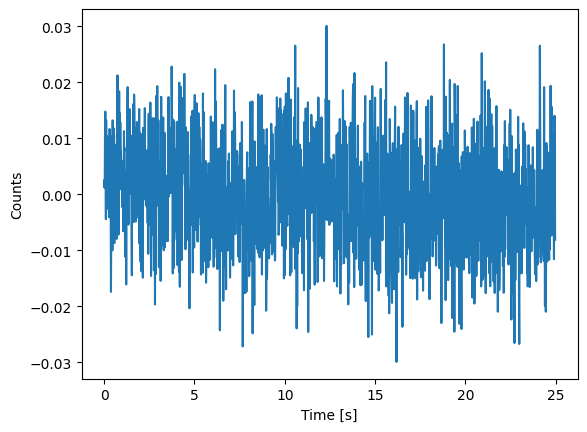

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2022-04-30_2479_77-21_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


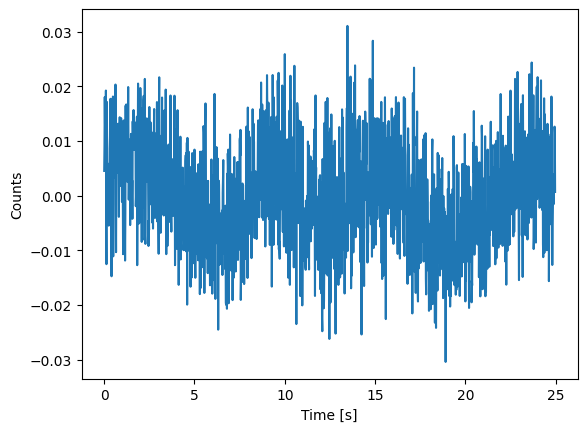

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8388_82-22_subscan6_S20mm-SPECPOL-ARRAYDATA-1.fits


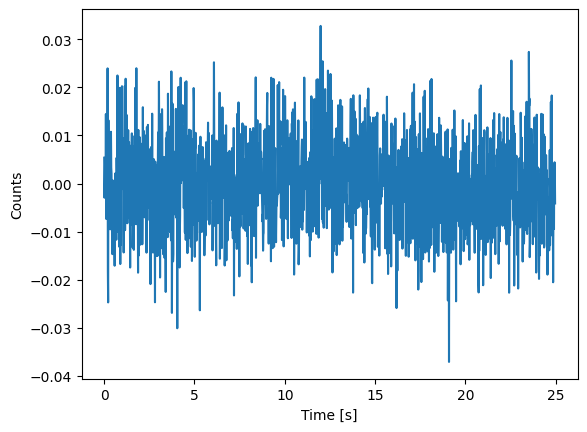

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8377_82-22_subscan3_S20mm-SPECPOL-ARRAYDATA-1.fits


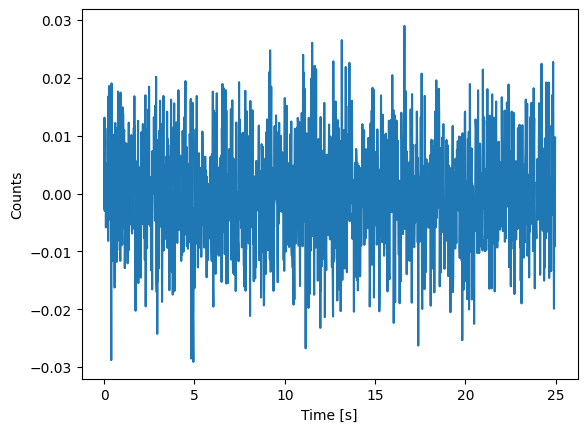

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8358_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


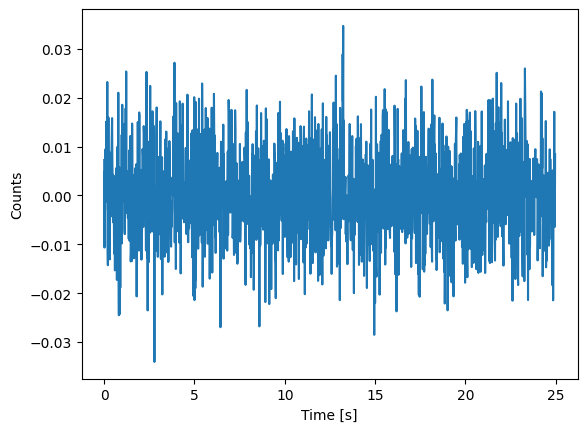

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8387_82-22_subscan4_S20mm-SPECPOL-ARRAYDATA-1.fits


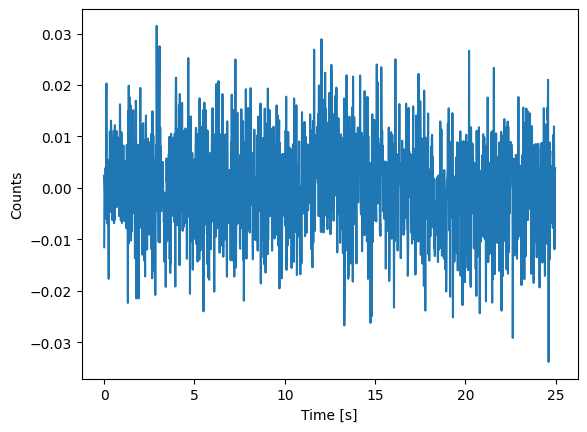

/workspace/data/TELAMON_Data/TELAMON_RawData/S20mm/DATA_2023-08-10_8377_82-22_subscan5_S20mm-SPECPOL-ARRAYDATA-1.fits


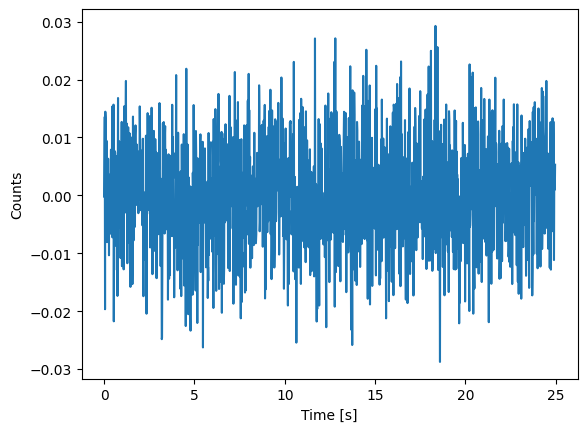

In [215]:
for o_lc in sorted_list_ocsvm[450:460]:  # Plot 5 random light curves from the cluster
    _, filename, lc = o_lc
    print(f'{filename}')
    plot_lc(lc)